In [1]:
# ============================================================
# JOB MARKET ANALYSIS AND RECOMMENDATION SYSTEM
# ============================================================

print("Job Market Analysis and Recommendation System")
print("Project Started Successfully")

Job Market Analysis and Recommendation System
Project Started Successfully


In [2]:
# Data Analysis
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
import re

from scipy.stats import pearsonr, spearmanr

import warnings
warnings.filterwarnings("ignore")
# Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Utilities
import warnings
warnings.filterwarnings("ignore")

print("All libraries imported successfully.")

All libraries imported successfully.


In [3]:
# Project configuration

DATA_PATH = "../data/all_upwork_jobs_2024-02-07-2024-03-24.csv"

print("Dataset path:")
print(DATA_PATH)

Dataset path:
../data/all_upwork_jobs_2024-02-07-2024-03-24.csv


In [4]:
df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Dataset loaded successfully!
Rows: 244828
Columns: 8


In [5]:
df.head()

,title,link,published_date,is_hourly,hourly_low,hourly_high,budget,country
0,Experienced Media Buyer For Solar Pannel and R...,https://www.upwork.com/jobs/Experienced-Media-...,2024-02-17 09:09:54+00:00,False,NaN,NaN,500.0,NaN
1,Full Stack Developer,https://www.upwork.com/jobs/Full-Stack-Develop...,2024-02-17 09:09:17+00:00,False,NaN,NaN,1100.0,United States
2,SMMA Bubble App,https://www.upwork.com/jobs/SMMA-Bubble-App_%7...,2024-02-17 09:08:46+00:00,True,10.0,30.0,NaN,United States
3,Talent Hunter Specialized in Marketing,https://www.upwork.com/jobs/Talent-Hunter-Spec...,2024-02-17 09:08:08+00:00,True,NaN,NaN,NaN,United States
4,Data Engineer,https://www.upwork.com/jobs/Data-Engineer_%7E0...,2024-02-17 09:07:42+00:00,False,NaN,NaN,650.0,India


In [6]:
df.tail()

,title,link,published_date,is_hourly,hourly_low,hourly_high,budget,country
244823,Need Facebook advertising experts to launch pr...,https://www.upwork.com/jobs/Need-Facebook-adve...,2024-03-24 13:28:38+00:00,True,20.0,100.0,NaN,Zambia
244824,Digital/Telemarketing/Sales/OutSide Sales,https://www.upwork.com/jobs/Digital-Telemarket...,2024-03-24 13:40:52+00:00,False,NaN,NaN,100.0,Sri Lanka
244825,WordPress Template Edits,https://www.upwork.com/jobs/WordPress-Template...,2024-03-24 13:37:50+00:00,True,5.0,30.0,NaN,United States
244826,ELEMENTOR PRO For quick fix (Wordpress),https://www.upwork.com/jobs/ELEMENTOR-PRO-For-...,2024-03-24 13:52:15+00:00,False,NaN,NaN,15.0,France
244827,Creating a UGC Ad for Our Mobile Game,https://www.upwork.com/jobs/Creating-UGC-for-O...,2024-03-24 13:53:00+00:00,False,NaN,NaN,50.0,Israel


In [7]:
df.shape

(244828, 8)

In [8]:
df.columns.tolist()

['title',
 'link',
 'published_date',
 'is_hourly',
 'hourly_low',
 'hourly_high',
 'budget',
 'country']

In [9]:
DATA_PATH = "../data/all_upwork_jobs_2024-02-07-2024-03-24.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [10]:
print("Number of Rows    :", df.shape[0])
print("Number of Columns :", df.shape[1])

Number of Rows    : 244828
Number of Columns : 8


In [11]:
df.head()

,title,link,published_date,is_hourly,hourly_low,hourly_high,budget,country
0,Experienced Media Buyer For Solar Pannel and R...,https://www.upwork.com/jobs/Experienced-Media-...,2024-02-17 09:09:54+00:00,False,NaN,NaN,500.0,NaN
1,Full Stack Developer,https://www.upwork.com/jobs/Full-Stack-Develop...,2024-02-17 09:09:17+00:00,False,NaN,NaN,1100.0,United States
2,SMMA Bubble App,https://www.upwork.com/jobs/SMMA-Bubble-App_%7...,2024-02-17 09:08:46+00:00,True,10.0,30.0,NaN,United States
3,Talent Hunter Specialized in Marketing,https://www.upwork.com/jobs/Talent-Hunter-Spec...,2024-02-17 09:08:08+00:00,True,NaN,NaN,NaN,United States
4,Data Engineer,https://www.upwork.com/jobs/Data-Engineer_%7E0...,2024-02-17 09:07:42+00:00,False,NaN,NaN,650.0,India


In [12]:
df.tail()

,title,link,published_date,is_hourly,hourly_low,hourly_high,budget,country
244823,Need Facebook advertising experts to launch pr...,https://www.upwork.com/jobs/Need-Facebook-adve...,2024-03-24 13:28:38+00:00,True,20.0,100.0,NaN,Zambia
244824,Digital/Telemarketing/Sales/OutSide Sales,https://www.upwork.com/jobs/Digital-Telemarket...,2024-03-24 13:40:52+00:00,False,NaN,NaN,100.0,Sri Lanka
244825,WordPress Template Edits,https://www.upwork.com/jobs/WordPress-Template...,2024-03-24 13:37:50+00:00,True,5.0,30.0,NaN,United States
244826,ELEMENTOR PRO For quick fix (Wordpress),https://www.upwork.com/jobs/ELEMENTOR-PRO-For-...,2024-03-24 13:52:15+00:00,False,NaN,NaN,15.0,France
244827,Creating a UGC Ad for Our Mobile Game,https://www.upwork.com/jobs/Creating-UGC-for-O...,2024-03-24 13:53:00+00:00,False,NaN,NaN,50.0,Israel


In [13]:
print("Dataset Columns:\n")

for i, column in enumerate(df.columns, start=1):
    print(f"{i}. {column}")

Dataset Columns:

1. title
2. link
3. published_date
4. is_hourly
5. hourly_low
6. hourly_high
7. budget
8. country


In [14]:
df.dtypes

title                 str
link                  str
published_date        str
is_hourly            bool
hourly_low        float64
hourly_high       float64
budget            float64
country               str
dtype: object

In [15]:
data_types = pd.DataFrame({
    "Column": df.columns,
    "Data_Type": df.dtypes.astype(str).values
})

data_types

,Column,Data_Type
0,title,str
1,link,str
2,published_date,str
3,is_hourly,bool
4,hourly_low,float64
5,hourly_high,float64
6,budget,float64
7,country,str


In [16]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 244828 entries, 0 to 244827
Data columns (total 8 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   title           244827 non-null  str    
 1   link            244827 non-null  str    
 2   published_date  244828 non-null  str    
 3   is_hourly       244828 non-null  bool   
 4   hourly_low      102422 non-null  float64
 5   hourly_high     98775 non-null   float64
 6   budget          103891 non-null  float64
 7   country         239751 non-null  str    
dtypes: bool(1), float64(3), str(4)
memory usage: 13.3 MB


In [17]:
df.describe()

,hourly_low,hourly_high,budget
count,102422.000000,98775.000000,103891.000000
mean,17.339644,41.970610,911.473564
std,18.140065,47.850892,15729.738834
min,3.000000,3.000000,5.000000
25%,8.000000,20.000000,25.000000
50%,15.000000,30.000000,100.000000
75%,20.000000,50.000000,300.000000
max,998.000000,999.000000,1000000.000000


In [18]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
title,244827,205470,Social Media Manager,419,NaN,NaN,NaN,NaN,NaN,NaN,NaN
link,244827,244827,https://www.upwork.com/jobs/Experienced-Media-...,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
published_date,244828,233640,2024-02-24 13:04:28+00:00,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN
is_hourly,244828,2,True,140937,NaN,NaN,NaN,NaN,NaN,NaN,NaN
hourly_low,102422.0,NaN,NaN,NaN,17.339644,18.140065,3.0,8.0,15.0,20.0,998.0
hourly_high,98775.0,NaN,NaN,NaN,41.97061,47.850892,3.0,20.0,30.0,50.0,999.0
budget,103891.0,NaN,NaN,NaN,911.473564,15729.738834,5.0,25.0,100.0,300.0,1000000.0
country,239751,212,United States,99834,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [19]:
missing_values = df.isnull().sum()

missing_values

title                  1
link                   1
published_date         0
is_hourly              0
hourly_low        142406
hourly_high       146053
budget            140937
country             5077
dtype: int64

In [20]:
missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_report = pd.DataFrame({
    "Missing_Count": missing_values,
    "Missing_Percentage": missing_percentage.round(2)
})

missing_report = missing_report.sort_values(
    by="Missing_Percentage",
    ascending=False
)

missing_report

,Missing_Count,Missing_Percentage
hourly_high,146053,59.66
hourly_low,142406,58.17
budget,140937,57.57
country,5077,2.07
is_hourly,0,0.00
published_date,0,0.00
link,1,0.00
title,1,0.00


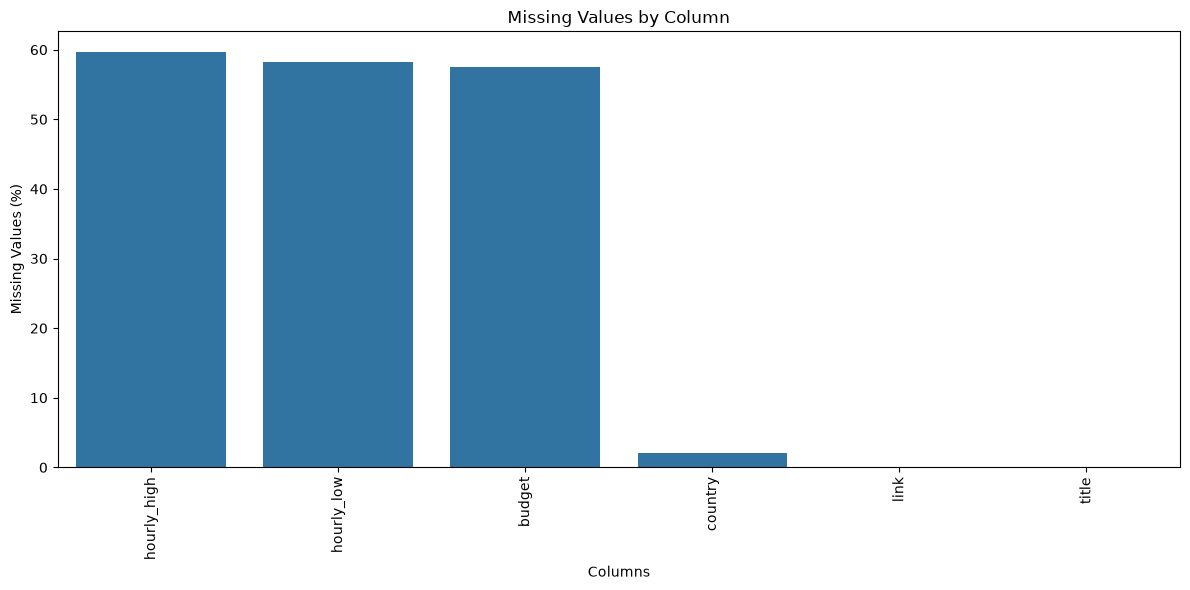

In [21]:
missing_plot = missing_report[
    missing_report["Missing_Count"] > 0
]

plt.figure(figsize=(12, 6))

sns.barplot(
    x=missing_plot.index,
    y=missing_plot["Missing_Percentage"]
)

plt.xticks(rotation=90)
plt.xlabel("Columns")
plt.ylabel("Missing Values (%)")
plt.title("Missing Values by Column")

plt.tight_layout()
plt.show()

In [22]:
duplicate_count = df.duplicated().sum()

print("Duplicate Records:", duplicate_count)

Duplicate Records: 0


In [23]:
duplicate_percentage = (duplicate_count / len(df)) * 100

print(
    f"Duplicate Percentage: {duplicate_percentage:.2f}%"
)

Duplicate Percentage: 0.00%


In [24]:
df = df.drop_duplicates().reset_index(drop=True)

print("Dataset shape after removing duplicates:")
print(df.shape)

Dataset shape after removing duplicates:
(244828, 8)


In [25]:
unique_report = pd.DataFrame({
    "Column": df.columns,
    "Unique_Values": [df[col].nunique() for col in df.columns]
})

unique_report.sort_values(
    by="Unique_Values",
    ascending=False
)

,Column,Unique_Values
1,link,244827
2,published_date,233640
0,title,205470
6,budget,768
5,hourly_high,227
7,country,212
4,hourly_low,114
3,is_hourly,2


In [26]:
constant_columns = [
    col for col in df.columns
    if df[col].nunique(dropna=False) <= 1
]

print("Constant Columns:")

if constant_columns:
    for col in constant_columns:
        print("-", col)
else:
    print("No constant columns found.")

Constant Columns:
No constant columns found.


In [27]:
if constant_columns:
    df.drop(columns=constant_columns, inplace=True)

print("Dataset shape:", df.shape)

Dataset shape: (244828, 8)


In [28]:
object_columns = df.select_dtypes(
    include=["object"]
).columns

for col in object_columns:
    df[col] = df[col].apply(
        lambda x: x.strip() if isinstance(x, str) else x
    )

print("Extra spaces cleaned from text columns.")

Extra spaces cleaned from text columns.


In [29]:
df.replace(
    r"^\s*$",
    np.nan,
    regex=True,
    inplace=True
)

print("Empty strings converted to NaN.")

Empty strings converted to NaN.


In [30]:
df.isnull().sum()

title                  1
link                   1
published_date         0
is_hourly              0
hourly_low        142406
hourly_high       146053
budget            140937
country             5077
dtype: int64

In [31]:
numeric_columns = df.select_dtypes(
    include=np.number
).columns.tolist()

print("Numeric Columns:")

for col in numeric_columns:
    print("-", col)

Numeric Columns:
- hourly_low
- hourly_high
- budget


In [32]:
categorical_columns = df.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Categorical Columns:")

for col in categorical_columns:
    print("-", col)

Categorical Columns:
- title
- link
- published_date
- country


In [33]:
outlier_summary = []

for col in numeric_columns:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ][col].count()

    outlier_summary.append({
        "Column": col,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Lower_Bound": lower_bound,
        "Upper_Bound": upper_bound,
        "Outlier_Count": outliers
    })

outlier_report = pd.DataFrame(outlier_summary)

outlier_report

,Column,Q1,Q3,IQR,Lower_Bound,Upper_Bound,Outlier_Count
0,hourly_low,8.0,20.0,12.0,-10.0,38.0,8450
1,hourly_high,20.0,50.0,30.0,-25.0,95.0,7029
2,budget,25.0,300.0,275.0,-387.5,712.5,12993


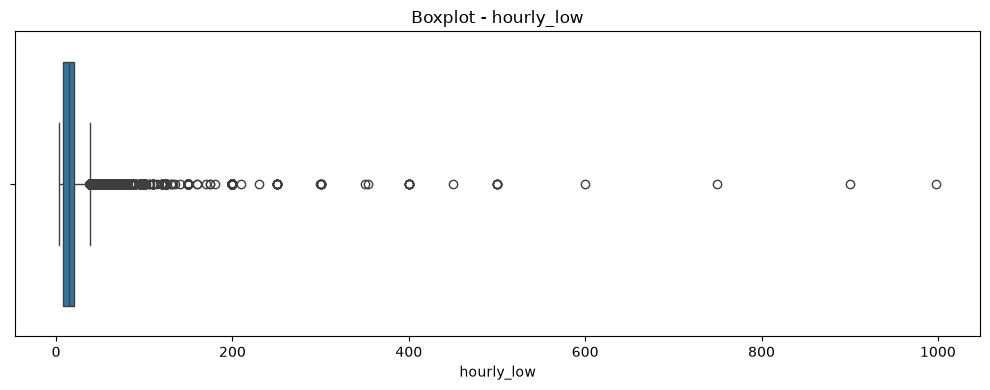

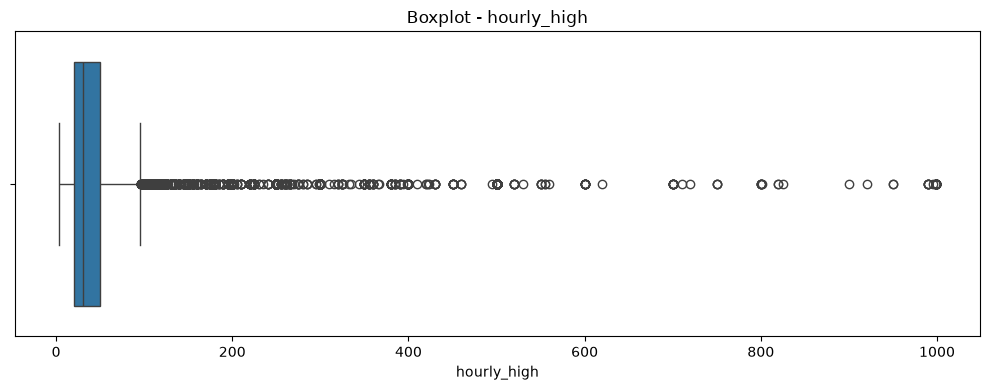

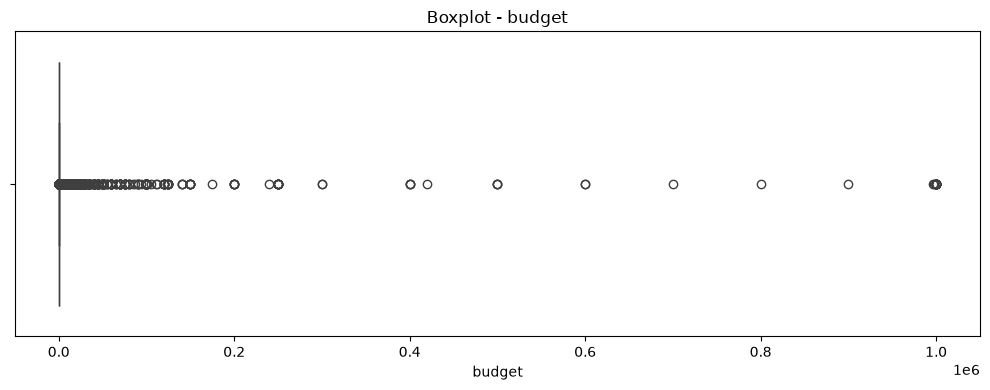

In [34]:
for col in numeric_columns:

    plt.figure(figsize=(10, 4))

    sns.boxplot(x=df[col])

    plt.title(f"Boxplot - {col}")
    plt.xlabel(col)

    plt.tight_layout()
    plt.show()

In [35]:
print("Final shape after basic cleaning:")
print(df.shape)

Final shape after basic cleaning:
(244828, 8)


In [36]:
final_missing_report = pd.DataFrame({
    "Column": df.columns,
    "Missing_Count": df.isnull().sum().values,
    "Missing_Percentage": (
        df.isnull().sum().values / len(df) * 100
    ).round(2)
})

final_missing_report = final_missing_report.sort_values(
    by="Missing_Percentage",
    ascending=False
)

final_missing_report

,Column,Missing_Count,Missing_Percentage
5,hourly_high,146053,59.66
4,hourly_low,142406,58.17
6,budget,140937,57.57
7,country,5077,2.07
3,is_hourly,0,0.00
2,published_date,0,0.00
1,link,1,0.00
0,title,1,0.00


In [37]:
data_quality_report = pd.DataFrame({
    "Metric": [
        "Total Rows",
        "Total Columns",
        "Duplicate Rows",
        "Total Missing Values",
        "Numeric Columns",
        "Categorical Columns"
    ],
    
    "Value": [
        len(df),
        len(df.columns),
        df.duplicated().sum(),
        df.isnull().sum().sum(),
        len(numeric_columns),
        len(categorical_columns)
    ]
})

data_quality_report

,Metric,Value
0,Total Rows,244828
1,Total Columns,8
2,Duplicate Rows,0
3,Total Missing Values,434475
4,Numeric Columns,3
5,Categorical Columns,4


In [38]:
CLEANED_DATA_PATH = "../data/cleaned_job_market_data.csv"

df.to_csv(
    CLEANED_DATA_PATH,
    index=False
)

print("Cleaned dataset saved successfully!")
print(CLEANED_DATA_PATH)

Cleaned dataset saved successfully!
../data/cleaned_job_market_data.csv


In [39]:
cleaned_df = pd.read_csv(CLEANED_DATA_PATH)

print("Cleaned dataset loaded successfully.")
print("Shape:", cleaned_df.shape)

cleaned_df.head()

Cleaned dataset loaded successfully.
Shape: (244828, 8)


,title,link,published_date,is_hourly,hourly_low,hourly_high,budget,country
0,Experienced Media Buyer For Solar Pannel and R...,https://www.upwork.com/jobs/Experienced-Media-...,2024-02-17 09:09:54+00:00,False,NaN,NaN,500.0,NaN
1,Full Stack Developer,https://www.upwork.com/jobs/Full-Stack-Develop...,2024-02-17 09:09:17+00:00,False,NaN,NaN,1100.0,United States
2,SMMA Bubble App,https://www.upwork.com/jobs/SMMA-Bubble-App_%7...,2024-02-17 09:08:46+00:00,True,10.0,30.0,NaN,United States
3,Talent Hunter Specialized in Marketing,https://www.upwork.com/jobs/Talent-Hunter-Spec...,2024-02-17 09:08:08+00:00,True,NaN,NaN,NaN,United States
4,Data Engineer,https://www.upwork.com/jobs/Data-Engineer_%7E0...,2024-02-17 09:07:42+00:00,False,NaN,NaN,650.0,India


In [40]:
# ============================================================
# STEP 3 - EXPLORATORY DATA ANALYSIS (EDA)
# ============================================================
pd.set_option("display.max_columns", None)

CLEANED_DATA_PATH = "../data/cleaned_job_market_data.csv"

df = pd.read_csv(CLEANED_DATA_PATH)

print("Cleaned dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Cleaned dataset loaded successfully!
Rows: 244828
Columns: 8


In [41]:
print("========== DATASET OVERVIEW ==========")

print("Number of Rows    :", df.shape[0])
print("Number of Columns :", df.shape[1])
print("Total Values      :", df.size)
print("Duplicate Rows     :", df.duplicated().sum())
print("Missing Values     :", df.isnull().sum().sum())

========== DATASET OVERVIEW ==========
Number of Rows    : 244828
Number of Columns : 8
Total Values      : 1958624
Duplicate Rows     : 0
Missing Values     : 434475


In [42]:
print("========== DATASET COLUMNS ==========\n")

for i, col in enumerate(df.columns, 1):
    print(f"{i}. {col}")

========== DATASET COLUMNS ==========

1. title
2. link
3. published_date
4. is_hourly
5. hourly_low
6. hourly_high
7. budget
8. country


In [43]:
dtype_report = pd.DataFrame({
    "Column": df.columns,
    "Data_Type": df.dtypes.astype(str).values,
    "Non_Null_Count": df.notnull().sum().values,
    "Unique_Values": df.nunique().values
})

dtype_report

,Column,Data_Type,Non_Null_Count,Unique_Values
0,title,str,244827,205470
1,link,str,244827,244827
2,published_date,str,244828,233640
3,is_hourly,bool,244828,2
4,hourly_low,float64,102422,114
5,hourly_high,float64,98775,227
6,budget,float64,103891,768
7,country,str,239751,212


In [44]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
title,244827,205470,Social Media Manager,419,NaN,NaN,NaN,NaN,NaN,NaN,NaN
link,244827,244827,https://www.upwork.com/jobs/Experienced-Media-...,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
published_date,244828,233640,2024-02-24 13:04:28+00:00,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN
is_hourly,244828,2,True,140937,NaN,NaN,NaN,NaN,NaN,NaN,NaN
hourly_low,102422.0,NaN,NaN,NaN,17.339644,18.140065,3.0,8.0,15.0,20.0,998.0
hourly_high,98775.0,NaN,NaN,NaN,41.97061,47.850892,3.0,20.0,30.0,50.0,999.0
budget,103891.0,NaN,NaN,NaN,911.473564,15729.738834,5.0,25.0,100.0,300.0,1000000.0
country,239751,212,United States,99834,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [45]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
hourly_low,102422.0,17.339644,18.140065,3.0,8.0,15.0,20.0,998.0
hourly_high,98775.0,41.970610,47.850892,3.0,20.0,30.0,50.0,999.0
budget,103891.0,911.473564,15729.738834,5.0,25.0,100.0,300.0,1000000.0


In [46]:
missing_analysis = pd.DataFrame({
    "Column": df.columns,
    "Missing_Count": df.isnull().sum().values,
    "Missing_Percentage": (
        df.isnull().sum().values / len(df) * 100
    ).round(2)
})

missing_analysis = missing_analysis.sort_values(
    by="Missing_Percentage",
    ascending=False
)

missing_analysis

,Column,Missing_Count,Missing_Percentage
5,hourly_high,146053,59.66
4,hourly_low,142406,58.17
6,budget,140937,57.57
7,country,5077,2.07
3,is_hourly,0,0.00
2,published_date,0,0.00
1,link,1,0.00
0,title,1,0.00


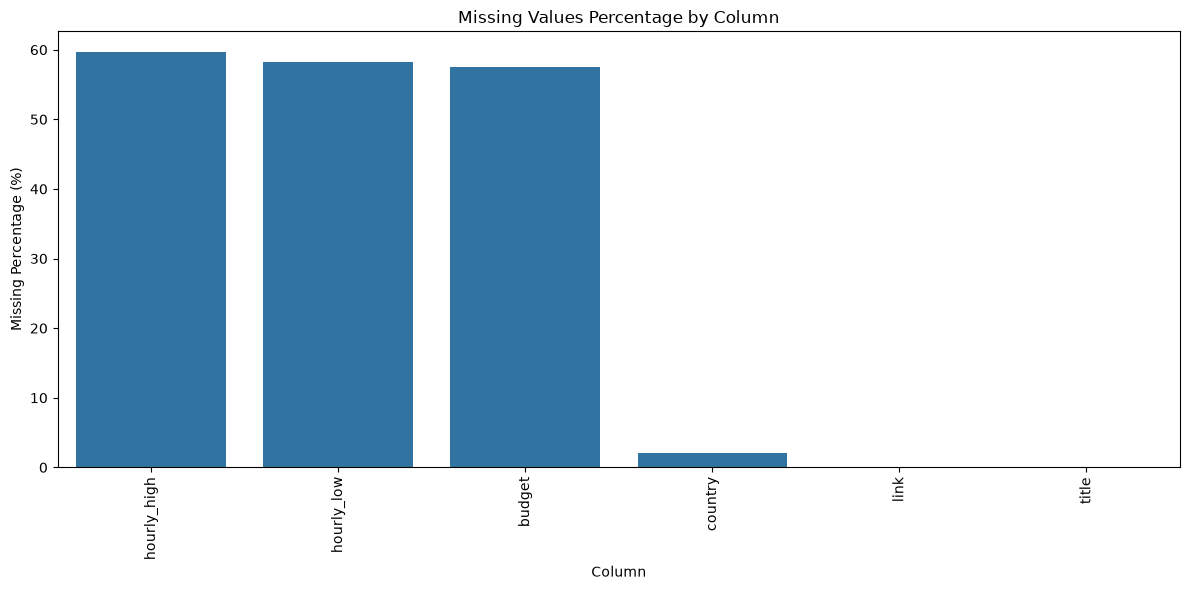

In [47]:
missing_plot = missing_analysis[
    missing_analysis["Missing_Count"] > 0
]

if len(missing_plot) > 0:

    plt.figure(figsize=(12, 6))

    sns.barplot(
        data=missing_plot,
        x="Column",
        y="Missing_Percentage"
    )

    plt.title("Missing Values Percentage by Column")
    plt.xlabel("Column")
    plt.ylabel("Missing Percentage (%)")
    plt.xticks(rotation=90)

    plt.tight_layout()
    plt.show()

else:
    print("No missing values found.")

In [48]:
numeric_columns = df.select_dtypes(
    include=np.number
).columns.tolist()

print("Numerical Columns:")
print(numeric_columns)

Numerical Columns:
['hourly_low', 'hourly_high', 'budget']


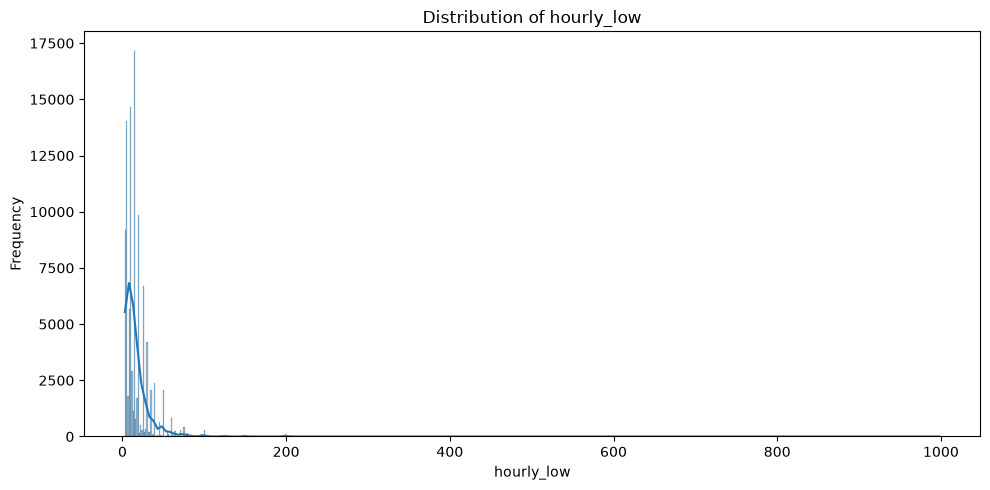

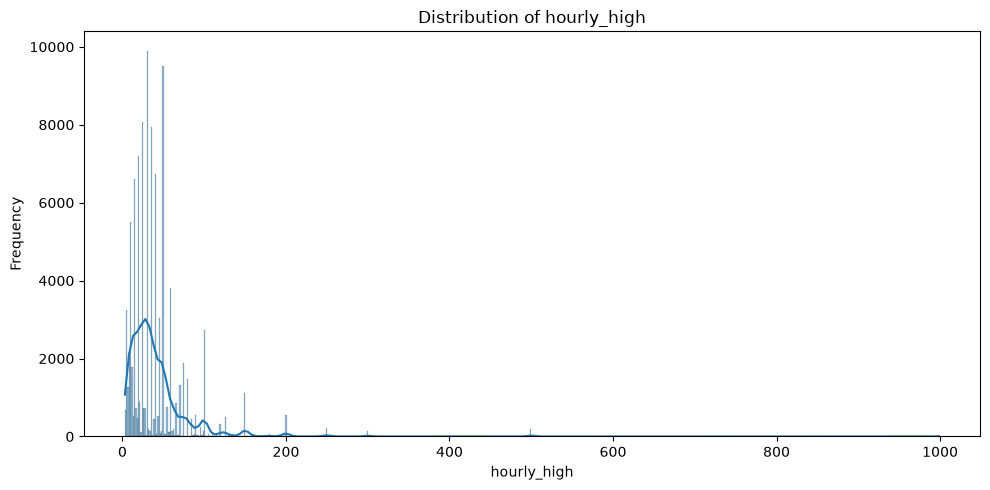

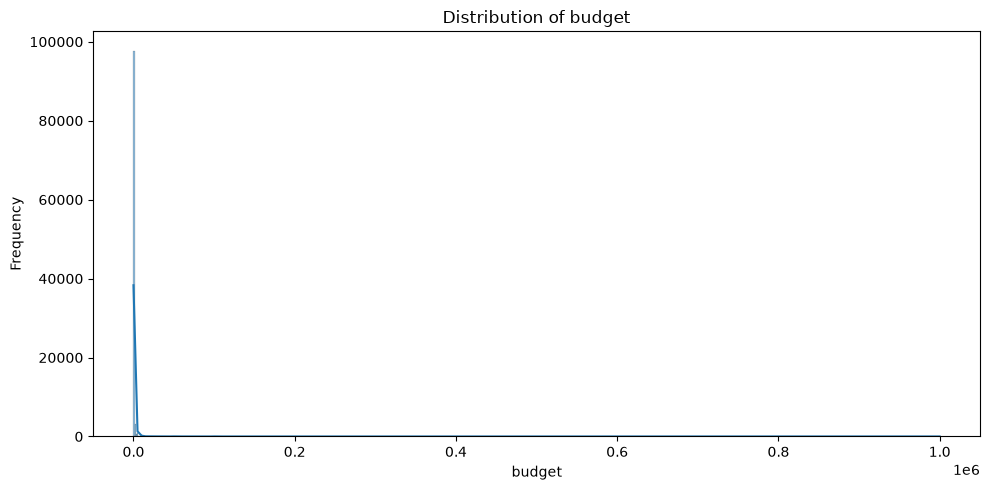

In [49]:
for col in numeric_columns:

    plt.figure(figsize=(10, 5))

    sns.histplot(
        data=df,
        x=col,
        kde=True
    )

    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")

    plt.tight_layout()
    plt.show()

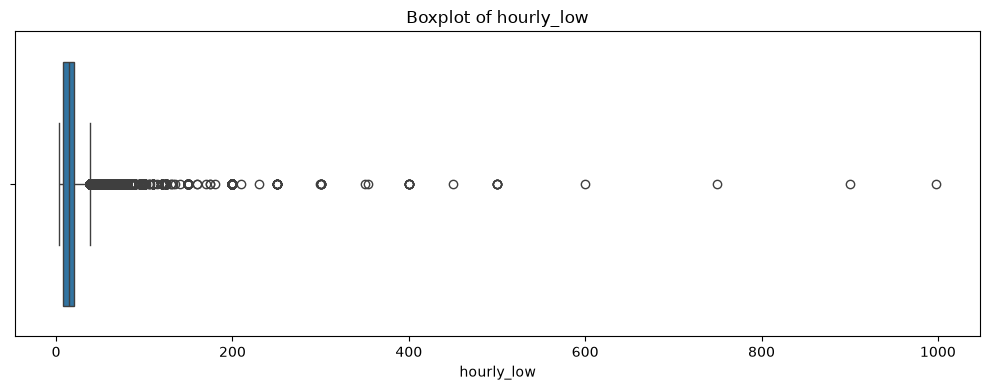

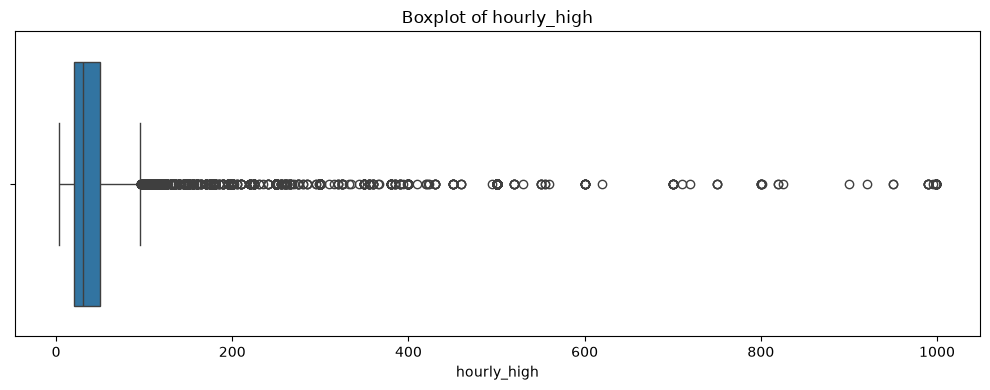

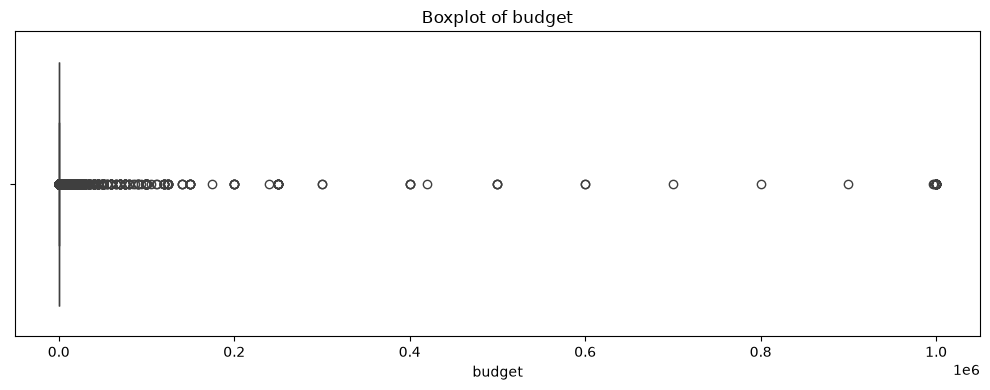

In [50]:
for col in numeric_columns:

    plt.figure(figsize=(10, 4))

    sns.boxplot(
        x=df[col]
    )

    plt.title(f"Boxplot of {col}")
    plt.xlabel(col)

    plt.tight_layout()
    plt.show()

In [51]:
categorical_columns = df.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Categorical Columns:")

for col in categorical_columns:
    print("-", col)

Categorical Columns:
- title
- link
- published_date
- country


In [52]:
for col in categorical_columns:

    print("\n" + "=" * 60)
    print(f"TOP VALUES - {col}")
    print("=" * 60)

    print(
        df[col]
        .value_counts(dropna=False)
        .head(10)
    )


TOP VALUES - title
title
Social Media Manager    419
Virtual Assistant       339
Logo Design             311
Video Editor            298
Graphic Designer        292
Logo design             173
Logo Designer           142
Full Stack Developer    136
Website Development     129
Appointment Setter      125
Name: count, dtype: int64

TOP VALUES - link
link
https://www.upwork.com/jobs/Experienced-Media-Buyer-For-Solar-Pannel-and-Roofing-installation-companies_%7E0173dd0447366e03d2?source=rss             1
https://www.upwork.com/jobs/Full-Stack-Developer_%7E011604a02b364315a8?source=rss                                                                    1
https://www.upwork.com/jobs/SMMA-Bubble-App_%7E0166a7749b263ff2e0?source=rss                                                                         1
https://www.upwork.com/jobs/Talent-Hunter-Specialized-Marketing_%7E016285f94066dffb31?source=rss                                                     1
https://www.upwork.com/jobs/Data-Enginee

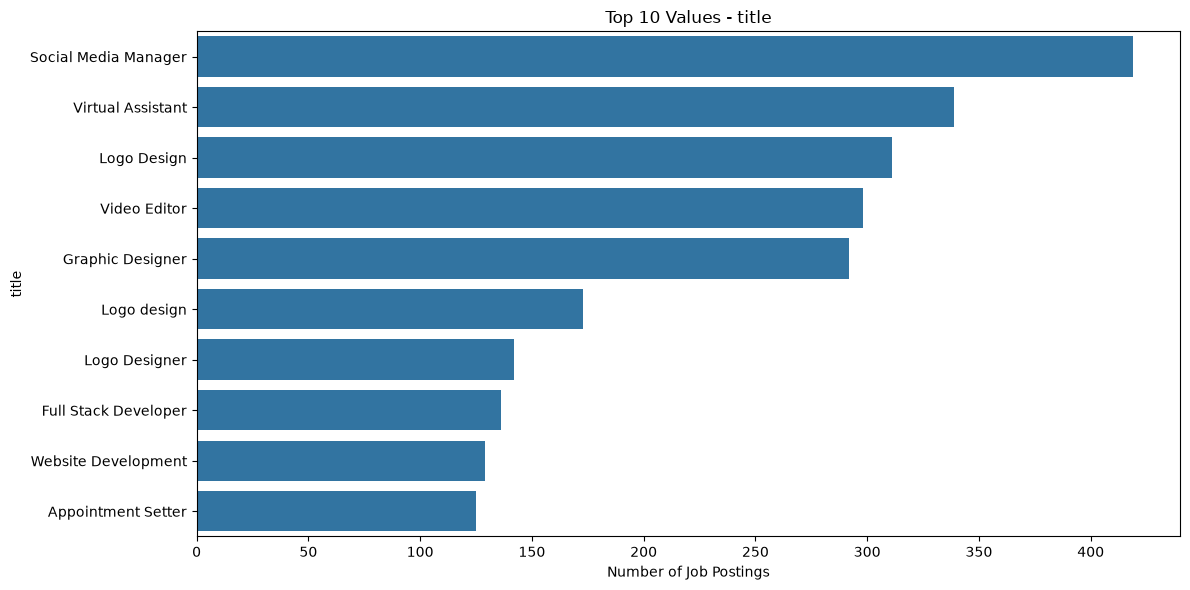

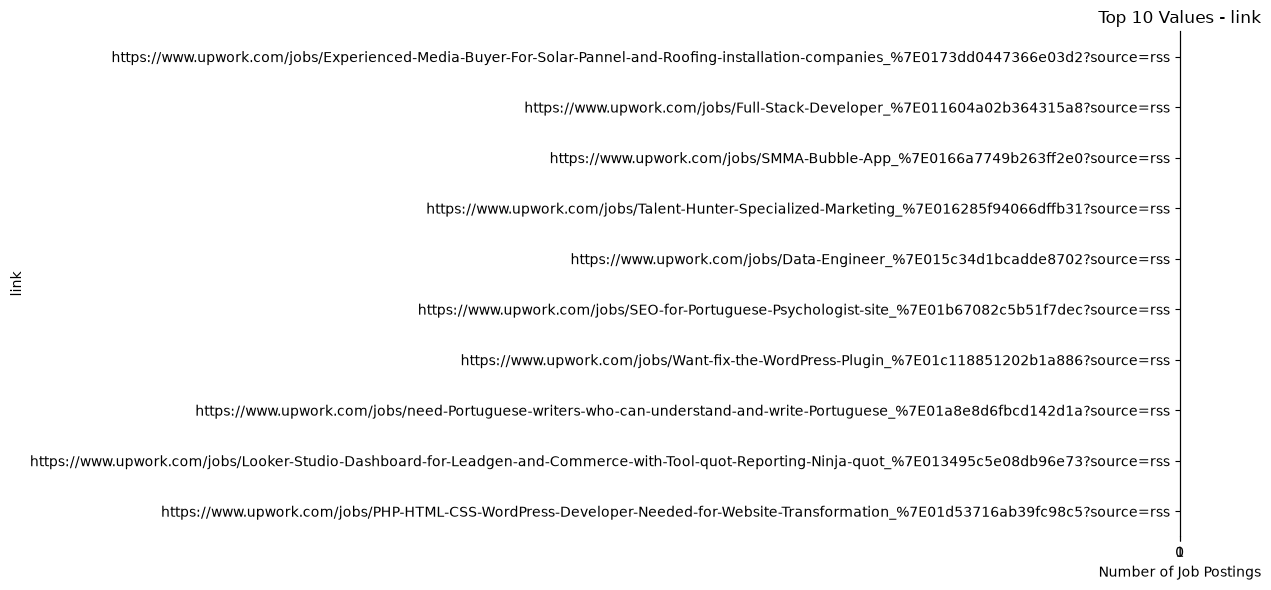

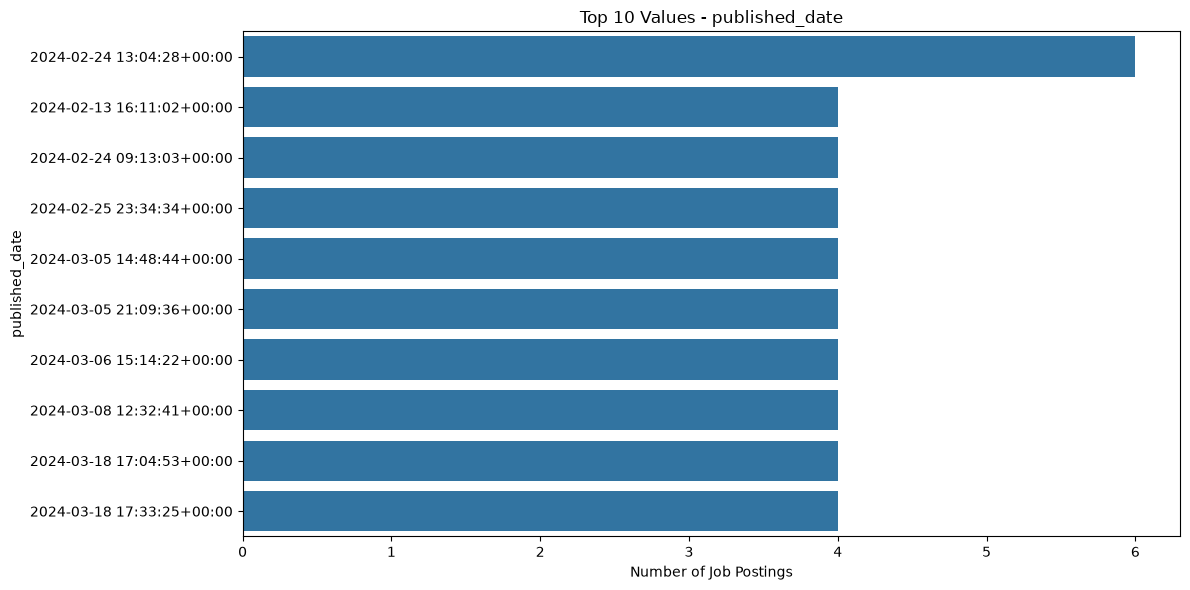

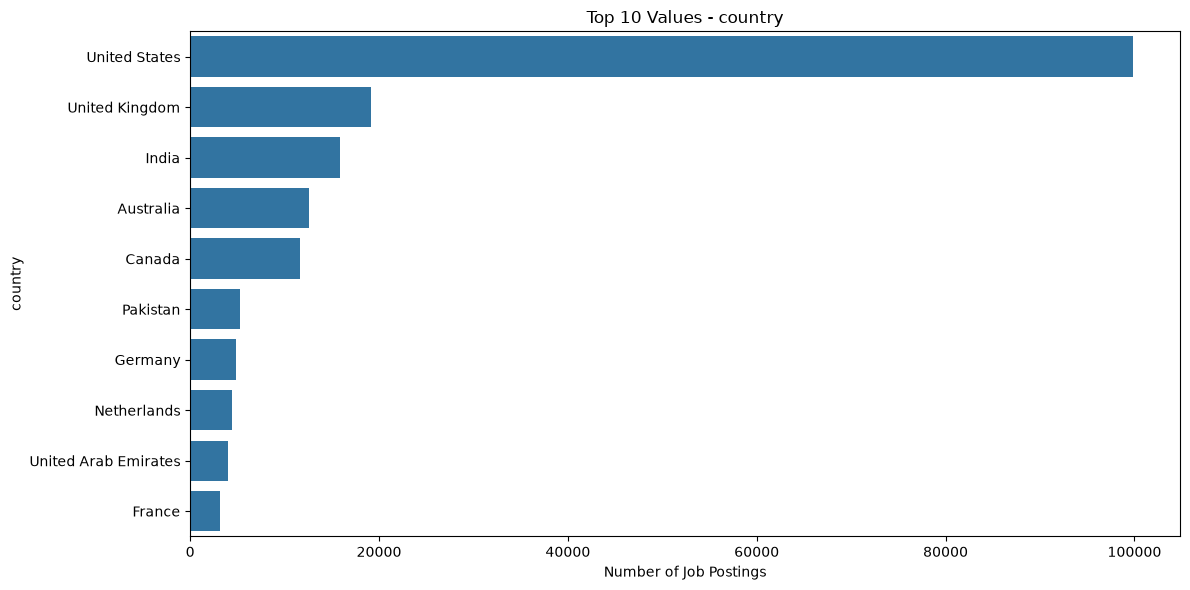

In [53]:
for col in categorical_columns:

    top_values = df[col].value_counts().head(10)

    plt.figure(figsize=(12, 6))

    sns.barplot(
        x=top_values.values,
        y=top_values.index
    )

    plt.title(f"Top 10 Values - {col}")
    plt.xlabel("Number of Job Postings")
    plt.ylabel(col)

    plt.tight_layout()
    plt.show()

In [54]:
if len(numeric_columns) >= 2:

    correlation_matrix = df[numeric_columns].corr()

    correlation_matrix

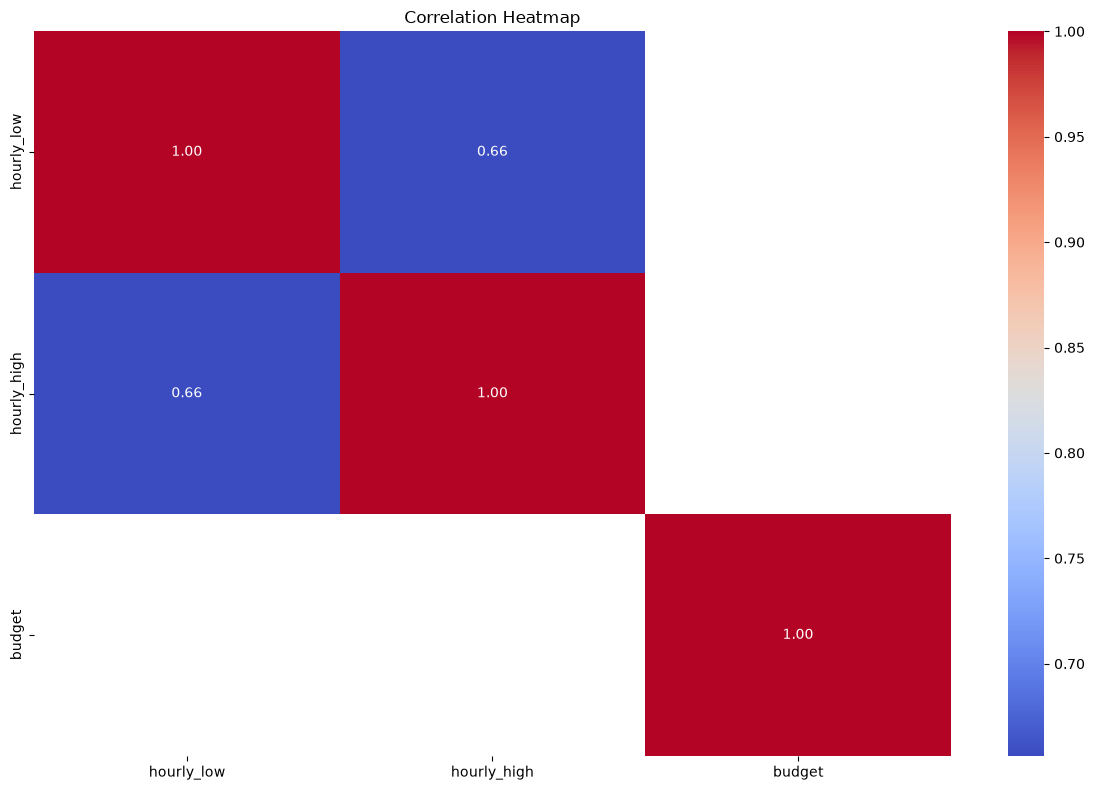

In [55]:
if len(numeric_columns) >= 2:

    plt.figure(figsize=(12, 8))

    sns.heatmap(
        correlation_matrix,
        annot=True,
        cmap="coolwarm",
        fmt=".2f"
    )

    plt.title("Correlation Heatmap")

    plt.tight_layout()
    plt.show()

In [56]:
possible_title_columns = [
    col for col in df.columns
    if any(
        keyword in col.lower()
        for keyword in [
            "title",
            "job_title",
            "jobtitle",
            "category",
            "job_category"
        ]
    )
]

print("Possible Job Title / Category Columns:")
print(possible_title_columns)

Possible Job Title / Category Columns:
['title']


In [57]:
JOB_TITLE_COLUMN = possible_title_columns[0]

print("Selected Job Title Column:", JOB_TITLE_COLUMN)

Selected Job Title Column: title


In [58]:
top_jobs = (
    df[JOB_TITLE_COLUMN]
    .value_counts()
    .head(20)
)

top_jobs

title
Social Media Manager                                                  419
Virtual Assistant                                                     339
Logo Design                                                           311
Video Editor                                                          298
Graphic Designer                                                      292
Logo design                                                           173
Logo Designer                                                         142
Full Stack Developer                                                  136
Website Development                                                   129
Appointment Setter                                                    125
Lead Generation                                                       121
Video editor                                                          112
SEO Specialist                                                        108
Social Media Marketing          

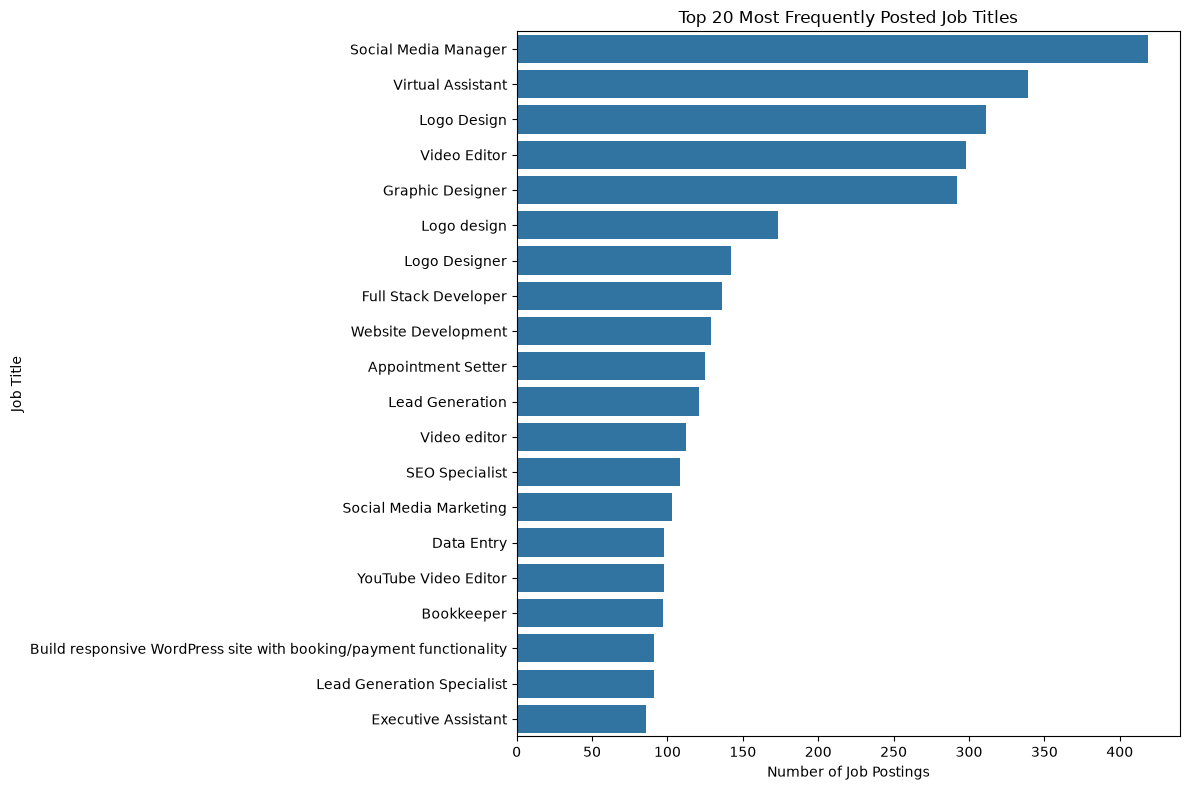

In [59]:
plt.figure(figsize=(12, 8))

sns.barplot(
    x=top_jobs.values,
    y=top_jobs.index
)

plt.title("Top 20 Most Frequently Posted Job Titles")
plt.xlabel("Number of Job Postings")
plt.ylabel("Job Title")

plt.tight_layout()
plt.show()

In [60]:
from collections import Counter
import re

all_titles = (
    df[JOB_TITLE_COLUMN]
    .dropna()
    .astype(str)
    .str.lower()
)

words = []

for title in all_titles:

    title_words = re.findall(
        r"\b[a-zA-Z]{3,}\b",
        title
    )

    words.extend(title_words)

word_frequency = Counter(words)

keyword_df = pd.DataFrame(
    word_frequency.most_common(30),
    columns=["Keyword", "Frequency"]
)

keyword_df

,Keyword,Frequency
0,for,73326
1,and,35443
2,needed,17592
3,website,16865
4,developer,16062
5,expert,15021
6,video,14138
7,with,13597
8,design,13269
9,designer,12957


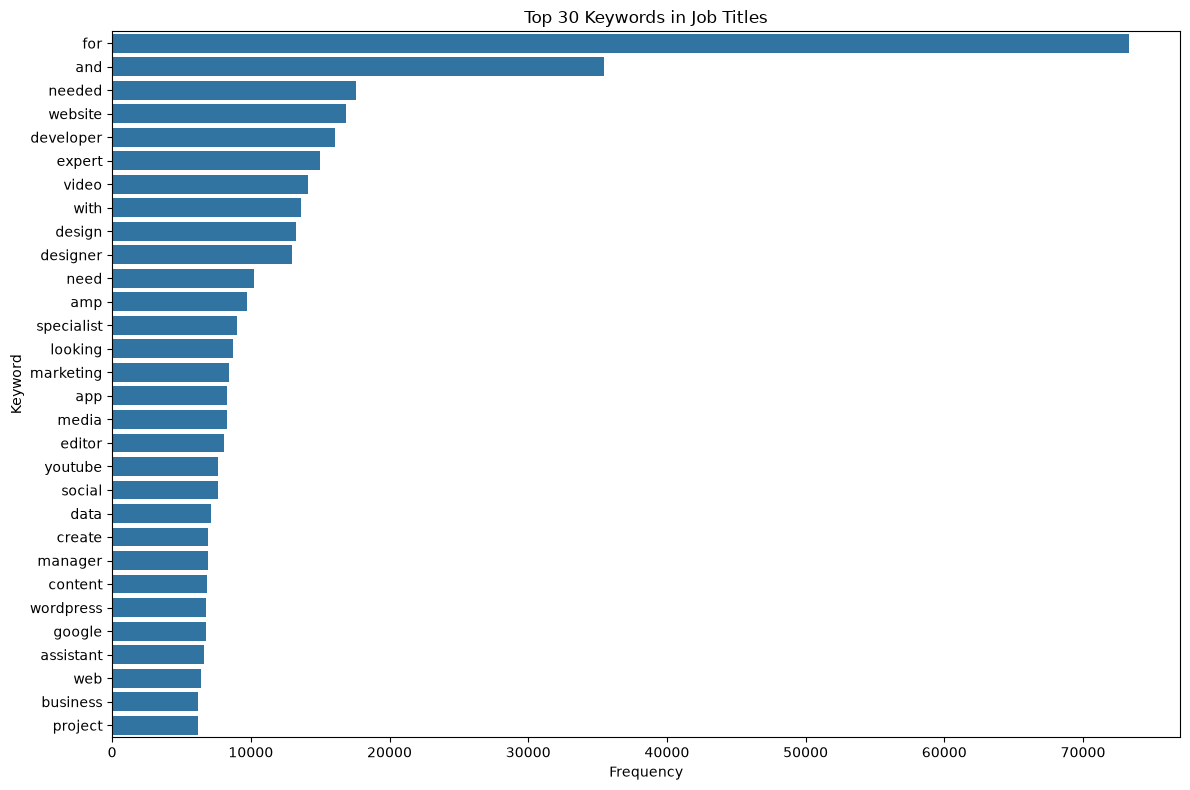

In [61]:
plt.figure(figsize=(12, 8))

sns.barplot(
    data=keyword_df,
    x="Frequency",
    y="Keyword"
)

plt.title("Top 30 Keywords in Job Titles")
plt.xlabel("Frequency")
plt.ylabel("Keyword")

plt.tight_layout()
plt.show()

In [62]:
possible_date_columns = [
    col for col in df.columns
    if any(
        keyword in col.lower()
        for keyword in [
            "date",
            "posted",
            "created",
            "time"
        ]
    )
]

print("Possible Date Columns:")
print(possible_date_columns)

Possible Date Columns:
['published_date']


In [63]:
DATE_COLUMN = possible_date_columns[0]

df[DATE_COLUMN] = pd.to_datetime(
    df[DATE_COLUMN],
    errors="coerce"
)

print(df[DATE_COLUMN].dtype)

datetime64[us, UTC]


In [64]:
if pd.api.types.is_datetime64_any_dtype(df[DATE_COLUMN]):

    monthly_jobs = (
        df.dropna(subset=[DATE_COLUMN])
        .groupby(
            df[DATE_COLUMN].dt.to_period("M")
        )
        .size()
        .reset_index(name="Job_Postings")
    )

    monthly_jobs[DATE_COLUMN] = (
        monthly_jobs[DATE_COLUMN]
        .astype(str)
    )

    monthly_jobs

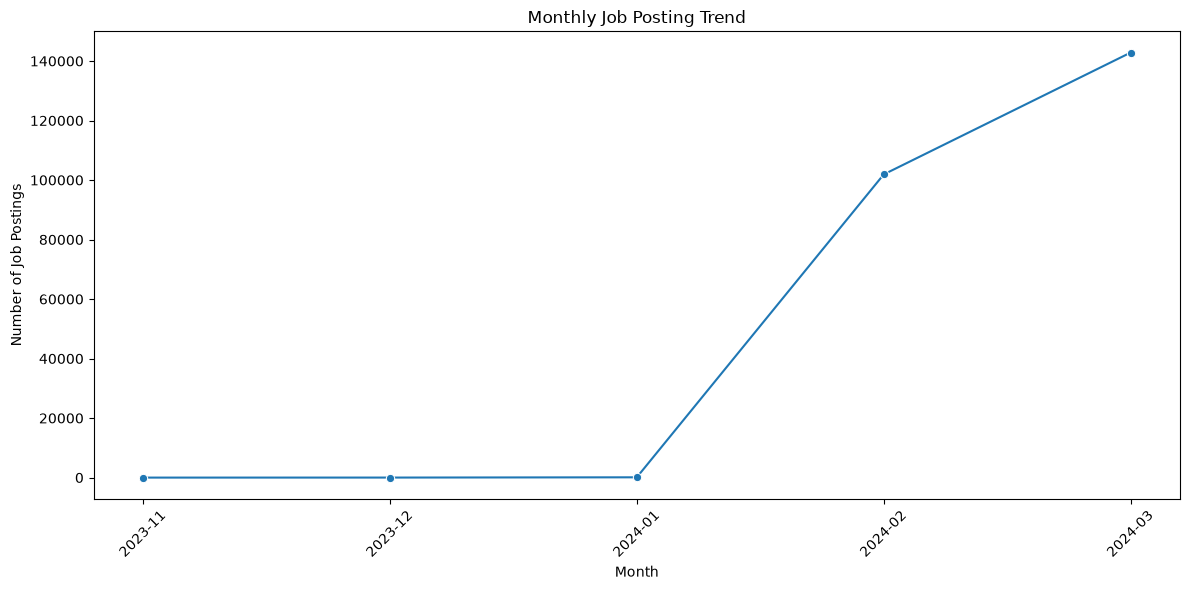

In [65]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=monthly_jobs,
    x=DATE_COLUMN,
    y="Job_Postings",
    marker="o"
)

plt.title("Monthly Job Posting Trend")
plt.xlabel("Month")
plt.ylabel("Number of Job Postings")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [66]:
possible_country_columns = [
    col for col in df.columns
    if any(
        keyword in col.lower()
        for keyword in [
            "country",
            "location",
            "client_country",
            "client_location"
        ]
    )
]

print("Possible Country / Location Columns:")
print(possible_country_columns)

Possible Country / Location Columns:
['country']


In [67]:
possible_remote_columns = [
    col for col in df.columns
    if any(
        keyword in col.lower()
        for keyword in [
            "remote",
            "work_type",
            "job_type",
            "location"
        ]
    )
]

print("Possible Remote / Work-Type Columns:")
print(possible_remote_columns)

Possible Remote / Work-Type Columns:
[]


In [68]:
print("=" * 70)
print("EDA SUMMARY")
print("=" * 70)

print("Total Jobs       :", len(df))
print("Total Columns    :", len(df.columns))
print("Numeric Columns  :", len(numeric_columns))
print("Categorical Cols :", len(categorical_columns))
print("Missing Values   :", df.isnull().sum().sum())
print("Duplicate Rows   :", df.duplicated().sum())

print("=" * 70)
print("EDA Completed Successfully!")
print("=" * 70)

EDA SUMMARY
Total Jobs       : 244828
Total Columns    : 8
Numeric Columns  : 3
Categorical Cols : 4
Missing Values   : 434475
Duplicate Rows   : 0
EDA Completed Successfully!


In [69]:
# ============================================================
# STEP 4 - TASK 1
# JOB TITLE KEYWORDS VS OFFERED SALARY
# ============================================================
CLEANED_DATA_PATH = "../data/cleaned_job_market_data.csv"

df = pd.read_csv(CLEANED_DATA_PATH)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (244828, 8)


In [70]:
possible_title_columns = [
    col for col in df.columns
    if any(
        keyword in col.lower()
        for keyword in [
            "title",
            "job_title",
            "jobtitle"
        ]
    )
]

print("Possible Job Title Columns:")
print(possible_title_columns)

Possible Job Title Columns:
['title']


In [71]:
JOB_TITLE_COLUMN = "title"

print("Job Title Column:", JOB_TITLE_COLUMN)

Job Title Column: title


In [72]:
possible_salary_columns = [
    col for col in df.columns
    if any(
        keyword in col.lower()
        for keyword in [
            "salary",
            "rate",
            "budget",
            "amount",
            "price",
            "hourly"
        ]
    )
]

print("Possible Salary / Rate Columns:")
print(possible_salary_columns)

Possible Salary / Rate Columns:
['is_hourly', 'hourly_low', 'hourly_high', 'budget']


In [73]:
for col in possible_salary_columns:
    print("\n" + "=" * 60)
    print("COLUMN:", col)
    print("=" * 60)
    print(df[col].head(10))


COLUMN: is_hourly
0    False
1    False
2     True
3     True
4    False
5     True
6    False
7     True
8     True
9    False
Name: is_hourly, dtype: bool

COLUMN: hourly_low
0     NaN
1     NaN
2    10.0
3     NaN
4     NaN
5     NaN
6     NaN
7     7.0
8     NaN
9     NaN
Name: hourly_low, dtype: float64

COLUMN: hourly_high
0     NaN
1     NaN
2    30.0
3     NaN
4     NaN
5     NaN
6     NaN
7    22.0
8     NaN
9     NaN
Name: hourly_high, dtype: float64

COLUMN: budget
0     500.0
1    1100.0
2       NaN
3       NaN
4     650.0
5       NaN
6       5.0
7       NaN
8       NaN
9     500.0
Name: budget, dtype: float64


In [74]:
SALARY_COLUMN = possible_salary_columns[0]

print("Selected Salary Column:", SALARY_COLUMN)

Selected Salary Column: is_hourly


In [75]:
salary_sample = df[
    [JOB_TITLE_COLUMN, SALARY_COLUMN]
].head(20)

salary_sample

,title,is_hourly
0,Experienced Media Buyer For Solar Pannel and R...,False
1,Full Stack Developer,False
2,SMMA Bubble App,True
3,Talent Hunter Specialized in Marketing,True
4,Data Engineer,False
5,SEO for Portuguese Psychologist site,True
6,Want to fix the WordPress Plugin,False
7,need Portuguese writers who can understand and...,True
8,Looker Studio Dashboard for Leadgen and E-Comm...,True
9,PHP/HTML/CSS WordPress Developer Needed for We...,False


In [76]:
def extract_numeric_salary(value):

    if pd.isna(value):
        return np.nan

    value = str(value)

    # Remove commas
    value = value.replace(",", "")

    # Extract numbers including decimals
    numbers = re.findall(r"\d+(?:\.\d+)?", value)

    if not numbers:
        return np.nan

    numbers = [float(x) for x in numbers]

    # If range is given, use average
    if len(numbers) >= 2:
        return np.mean(numbers[:2])

    return numbers[0]

In [77]:
df["offered_salary"] = df[SALARY_COLUMN].apply(
    extract_numeric_salary
)

df[
    [SALARY_COLUMN, "offered_salary"]
].head(20)

,is_hourly,offered_salary
0,False,NaN
1,False,NaN
2,True,NaN
3,True,NaN
4,False,NaN
5,True,NaN
6,False,NaN
7,True,NaN
8,True,NaN
9,False,NaN


In [78]:
print("Total records:", len(df))

print(
    "Valid salary records:",
    df["offered_salary"].notna().sum()
)

print(
    "Missing salary records:",
    df["offered_salary"].isna().sum()
)

Total records: 244828
Valid salary records: 0
Missing salary records: 244828


In [79]:
salary_missing_percentage = (
    df["offered_salary"].isna().mean() * 100
)

print(
    f"Missing salary percentage: "
    f"{salary_missing_percentage:.2f}%"
)

Missing salary percentage: 100.00%


In [80]:
salary_df = df[
    df["offered_salary"].notna()
].copy()

print("Salary Analysis Dataset Shape:")
print(salary_df.shape)

Salary Analysis Dataset Shape:
(0, 9)


In [81]:
salary_df["offered_salary"].describe()

count    0.0
mean     NaN
std      NaN
min      NaN
25%      NaN
50%      NaN
75%      NaN
max      NaN
Name: offered_salary, dtype: float64

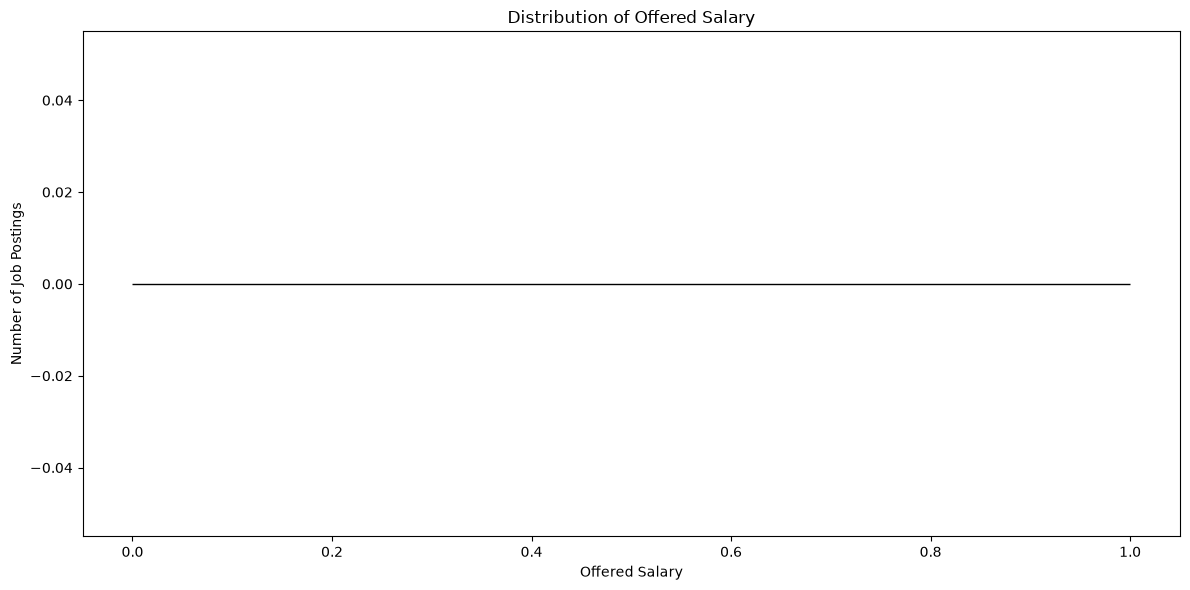

In [82]:
plt.figure(figsize=(12, 6))

sns.histplot(
    data=salary_df,
    x="offered_salary",
    kde=True
)

plt.title("Distribution of Offered Salary")
plt.xlabel("Offered Salary")
plt.ylabel("Number of Job Postings")

plt.tight_layout()
plt.show()

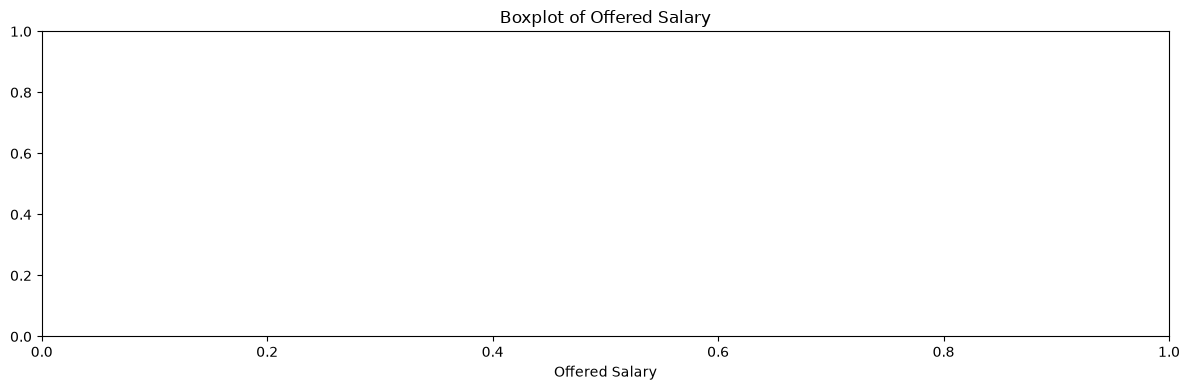

In [83]:
plt.figure(figsize=(12, 4))

sns.boxplot(
    x=salary_df["offered_salary"]
)

plt.title("Boxplot of Offered Salary")
plt.xlabel("Offered Salary")

plt.tight_layout()
plt.show()

In [84]:
Q1 = salary_df["offered_salary"].quantile(0.25)
Q3 = salary_df["offered_salary"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

Q1: nan
Q3: nan
IQR: nan
Lower Bound: nan
Upper Bound: nan


In [85]:
salary_outliers = salary_df[
    (salary_df["offered_salary"] < lower_bound) |
    (salary_df["offered_salary"] > upper_bound)
]

print("Salary Outliers:", len(salary_outliers))

Salary Outliers: 0


In [86]:
salary_df["clean_job_title"] = (
    salary_df[JOB_TITLE_COLUMN]
    .astype(str)
    .str.lower()
    .str.strip()
)

In [87]:
stop_words = {
    "and", "the", "for", "with",
    "from", "you", "your",
    "job", "need", "looking",
    "to", "of", "a", "an",
    "in", "on", "is"
}

In [88]:
def extract_keywords(title):

    words = re.findall(
        r"\b[a-zA-Z]{3,}\b",
        title.lower()
    )

    keywords = [
        word
        for word in words
        if word not in stop_words
    ]

    return keywords

In [89]:
salary_df["keywords"] = (
    salary_df["clean_job_title"]
    .apply(extract_keywords)
)

salary_df[
    ["clean_job_title", "keywords"]
].head(20)

,clean_job_title,keywords


In [90]:
from collections import Counter

keyword_counter = Counter()

for keywords in salary_df["keywords"]:
    keyword_counter.update(keywords)

keyword_frequency = pd.DataFrame(
    keyword_counter.most_common(30),
    columns=["Keyword", "Frequency"]
)

keyword_frequency

,Keyword,Frequency


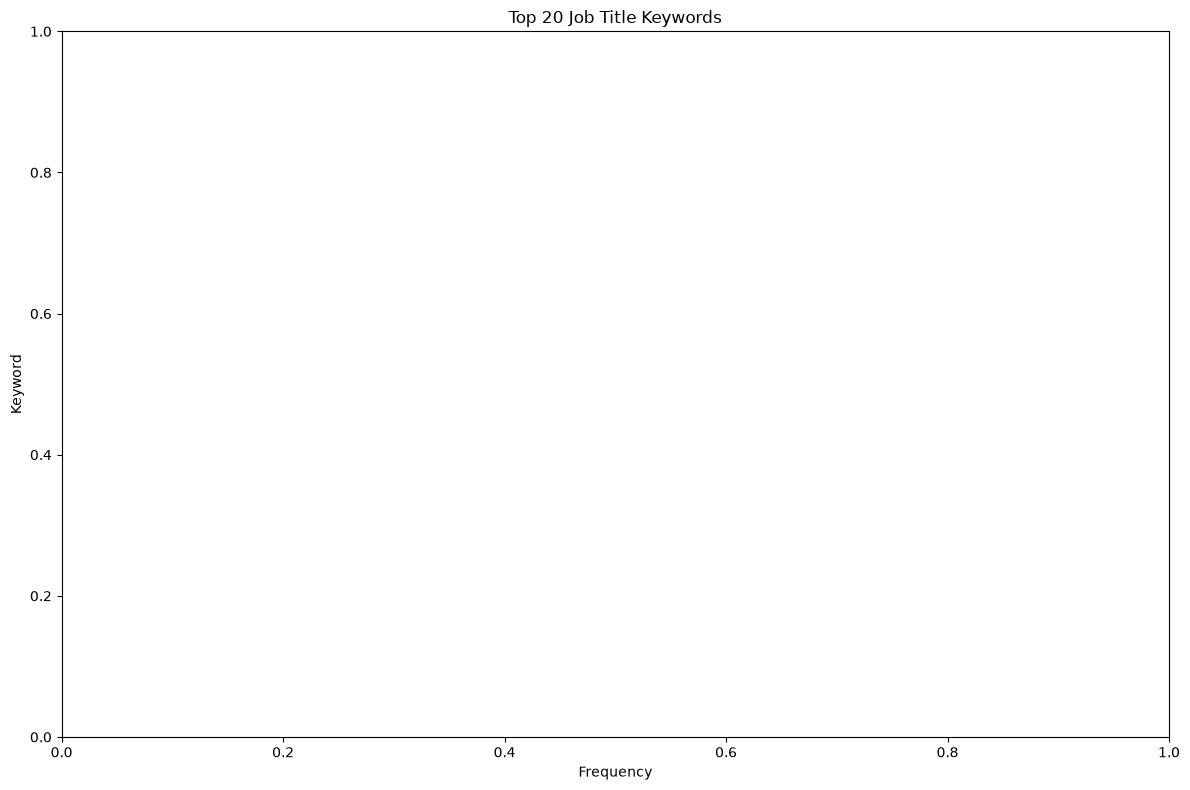

In [91]:
top_keywords = keyword_frequency.head(20)

plt.figure(figsize=(12, 8))

sns.barplot(
    data=top_keywords,
    x="Frequency",
    y="Keyword"
)

plt.title("Top 20 Job Title Keywords")
plt.xlabel("Frequency")
plt.ylabel("Keyword")

plt.tight_layout()
plt.show()

In [92]:
keyword_salary_records = []

for keyword in keyword_counter.keys():

    mask = salary_df["clean_job_title"].str.contains(
        rf"\b{re.escape(keyword)}\b",
        case=False,
        regex=True,
        na=False
    )

    matching_jobs = salary_df[mask]

    if len(matching_jobs) >= 5:

        keyword_salary_records.append({
            "Keyword": keyword,
            "Job_Postings": len(matching_jobs),
            "Average_Salary": matching_jobs["offered_salary"].mean(),
            "Median_Salary": matching_jobs["offered_salary"].median(),
            "Minimum_Salary": matching_jobs["offered_salary"].min(),
            "Maximum_Salary": matching_jobs["offered_salary"].max()
        })

keyword_salary_df = pd.DataFrame(
    keyword_salary_records
)

keyword_salary_df.head()

""


In [93]:
if "Average_Salary" in keyword_salary_df.columns and not keyword_salary_df.empty:
    keyword_salary_df = (
        keyword_salary_df.sort_values(
            by="Average_Salary",
            ascending=False
        )
        .reset_index(drop=True)
    )
else:
    print("No valid salary data available yet; check the salary extraction step.")

keyword_salary_df.head(20)

No valid salary data available yet; check the salary extraction step.


""


No valid salary data available for plotting. Check the salary extraction step and keyword aggregation.


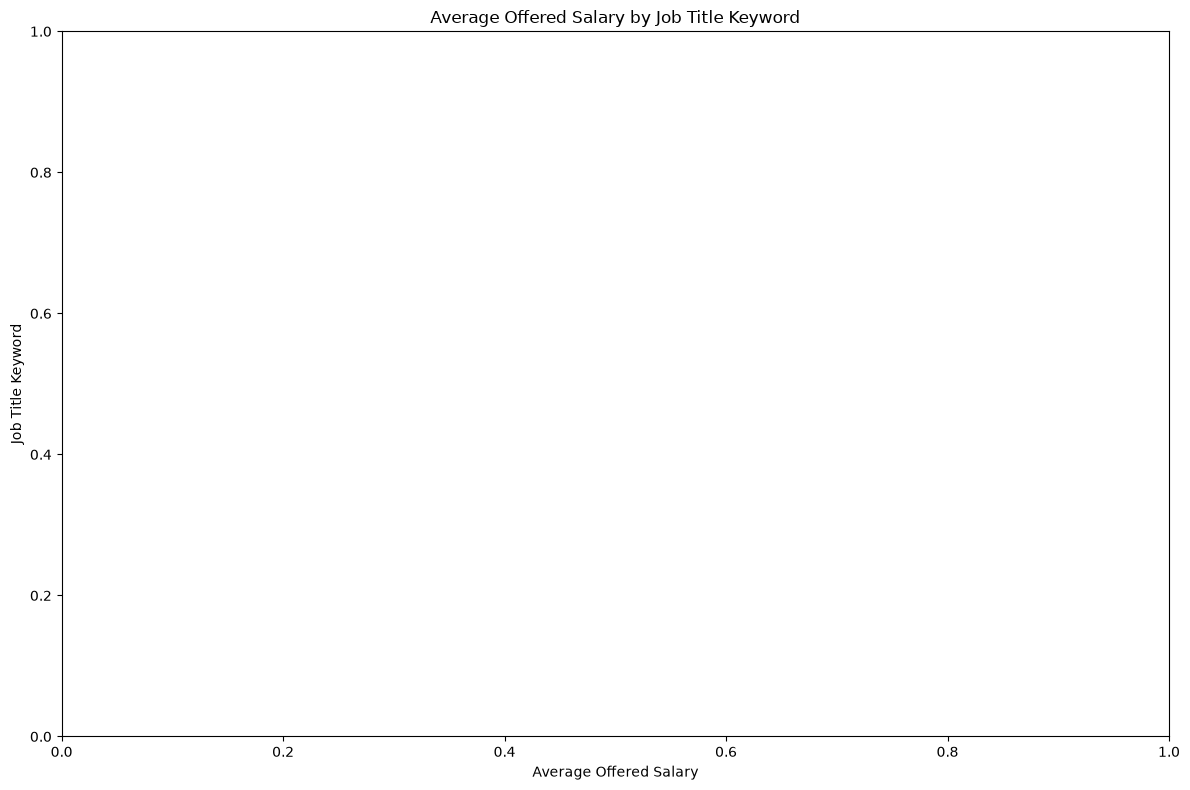

In [94]:
top_salary_keywords = keyword_salary_df.head(20)

plt.figure(figsize=(12, 8))

if "Average_Salary" in keyword_salary_df.columns and not keyword_salary_df.empty:
    top_salary_keywords = (
        keyword_salary_df
        .sort_values(by="Average_Salary", ascending=False)
        .head(20)
    )

    sns.barplot(
        data=top_salary_keywords,
        x="Average_Salary",
        y="Keyword",
        palette="viridis"
    )
else:
    print("No valid salary data available for plotting. Check the salary extraction step and keyword aggregation.")

plt.title(
    "Average Offered Salary by Job Title Keyword"
)

plt.xlabel("Average Offered Salary")
plt.ylabel("Job Title Keyword")

plt.tight_layout()
plt.show()

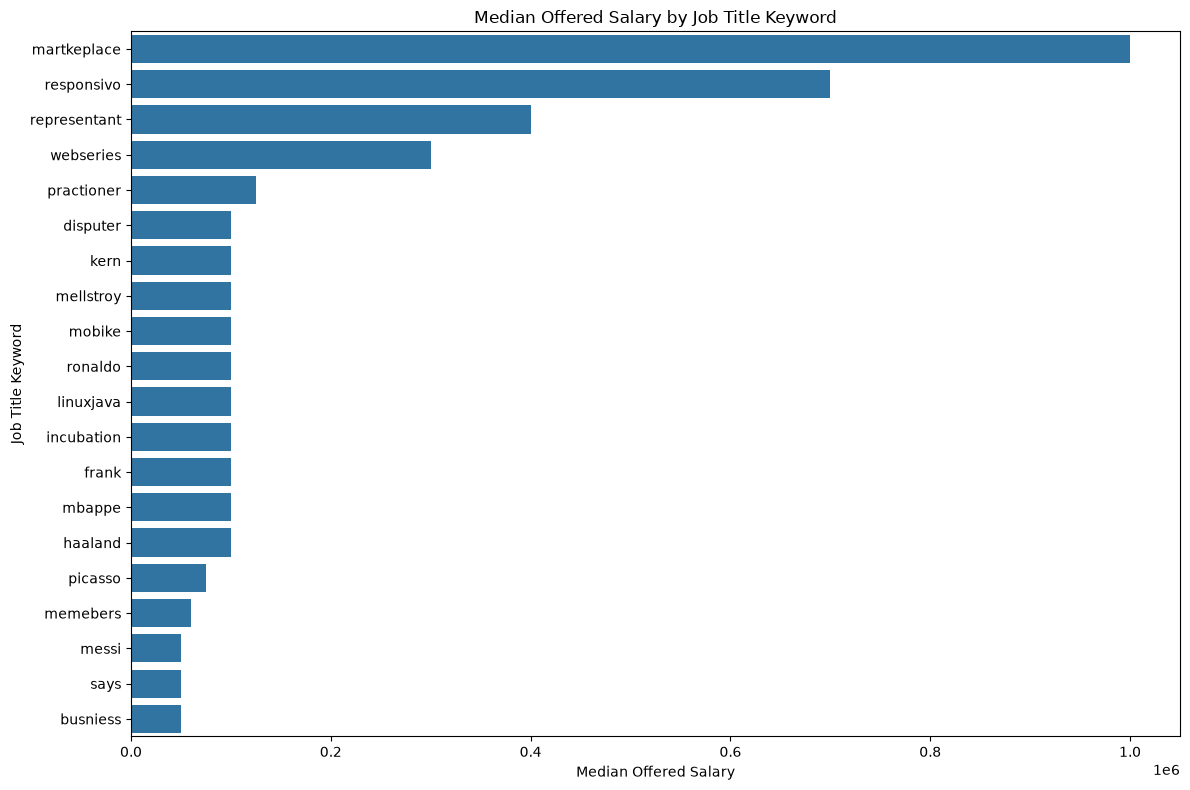

In [95]:
# Build the median-salary ranking safely and avoid KeyError if the column is missing
if "keyword_salary_df" not in globals() or keyword_salary_df.empty:
    # Fallback: build keyword salary summaries from valid salary rows
    if "clean_job_title" not in df.columns:
        df["clean_job_title"] = (
            df["title"].fillna("").astype(str).str.lower().str.strip()
        )

    if "offered_salary" not in df.columns or df["offered_salary"].isna().all():
        salary_cols = [c for c in ["hourly_low", "hourly_high", "budget"] if c in df.columns]
        if not salary_cols:
            raise ValueError("keyword_salary_df is empty; build it from valid salary data first.")

        df[salary_cols] = df[salary_cols].apply(pd.to_numeric, errors="coerce")
        df["offered_salary"] = df[salary_cols].bfill(axis=1).iloc[:, 0]

    valid_salary = df[df["offered_salary"].notna()].copy()
    if valid_salary.empty:
        raise ValueError("keyword_salary_df is empty; build it from valid salary data first.")

    rows = []
    stop_words = {
        "and", "the", "for", "with", "from", "your", "you",
        "job", "need", "looking", "to", "of", "a", "an", "in", "on", "is"
    }

    for _, row in valid_salary[["clean_job_title", "offered_salary"]].dropna().iterrows():
        words = re.findall(r"\b[a-zA-Z]{3,}\b", str(row["clean_job_title"]).lower())
        keywords = {w for w in words if w not in stop_words}
        for kw in keywords:
            rows.append({
                "Keyword": kw,
                "offered_salary": float(row["offered_salary"])
            })

    if not rows:
        raise ValueError("keyword_salary_df is empty; build it from valid salary data first.")

    keyword_salary_df = (
        pd.DataFrame(rows)
        .groupby("Keyword", as_index=False)["offered_salary"]
        .agg(
            Job_Postings="size",
            Average_Salary="mean",
            Median_Salary="median",
            Minimum_Salary="min",
            Maximum_Salary="max"
        )
        .sort_values("Average_Salary", ascending=False)
        .reset_index(drop=True)
    )

if "Median_Salary" not in keyword_salary_df.columns:
    if "offered_salary" in df.columns and df["offered_salary"].notna().any():
        keyword_salary_df = (
            df[df["offered_salary"].notna()]
            .groupby("clean_job_title", dropna=False)
            .agg(
                Job_Postings=("offered_salary", "size"),
                Average_Salary=("offered_salary", "mean"),
                Median_Salary=("offered_salary", "median"),
                Minimum_Salary=("offered_salary", "min"),
                Maximum_Salary=("offered_salary", "max")
            )
            .reset_index()
            .rename(columns={"clean_job_title": "Keyword"})
        )
    else:
        raise KeyError("Median_Salary is not available and no valid offered_salary data exists.")

top_median_keywords = (
    keyword_salary_df
    .dropna(subset=["Median_Salary"])
    .sort_values(by="Median_Salary", ascending=False)
    .head(20)
    .reset_index(drop=True)
)

plt.figure(figsize=(12, 8))

sns.barplot(
    data=top_median_keywords,
    x="Median_Salary",
    y="Keyword"
)

plt.title(
    "Median Offered Salary by Job Title Keyword"
)

plt.xlabel("Median Offered Salary")
plt.ylabel("Job Title Keyword")

plt.tight_layout()
plt.show()

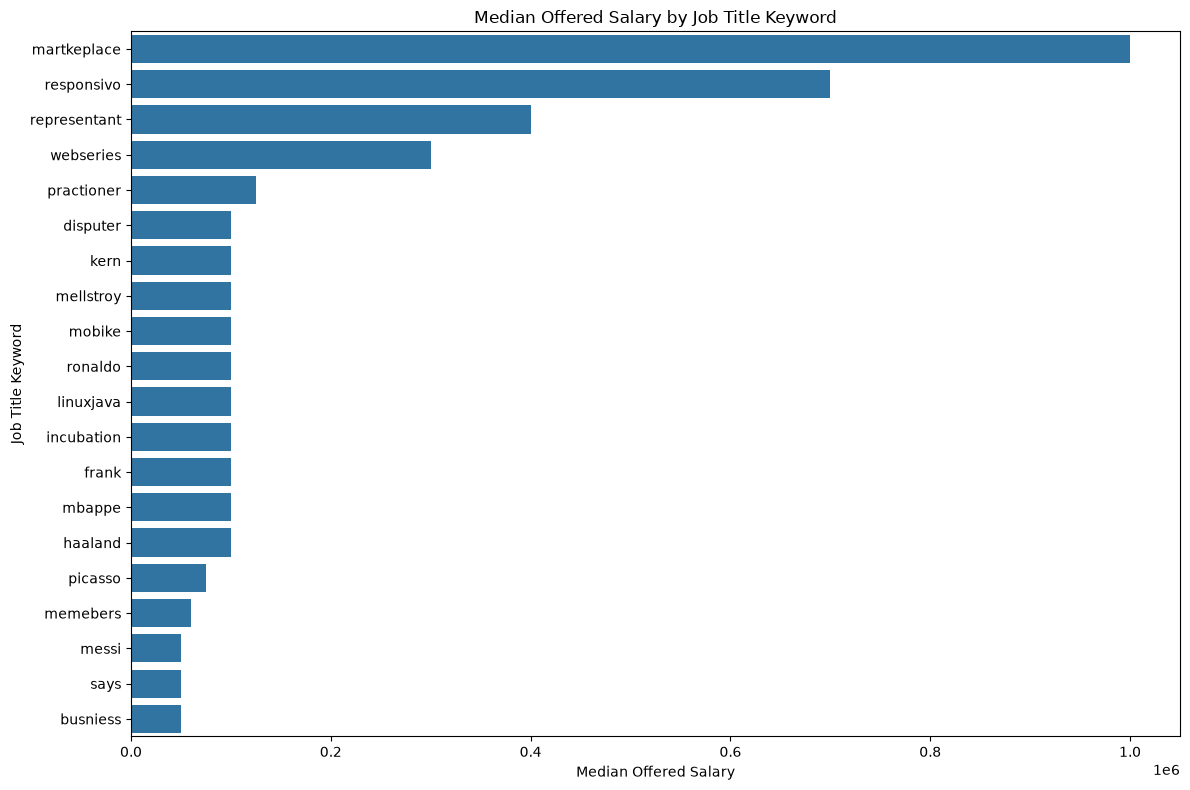

In [96]:
top_median_keywords = (
    keyword_salary_df
    .sort_values(
        by="Median_Salary",
        ascending=False
    )
    .head(20)
)

plt.figure(figsize=(12, 8))

sns.barplot(
    data=top_median_keywords,
    x="Median_Salary",
    y="Keyword"
)

plt.title(
    "Median Offered Salary by Job Title Keyword"
)

plt.xlabel("Median Offered Salary")
plt.ylabel("Job Title Keyword")

plt.tight_layout()
plt.show()

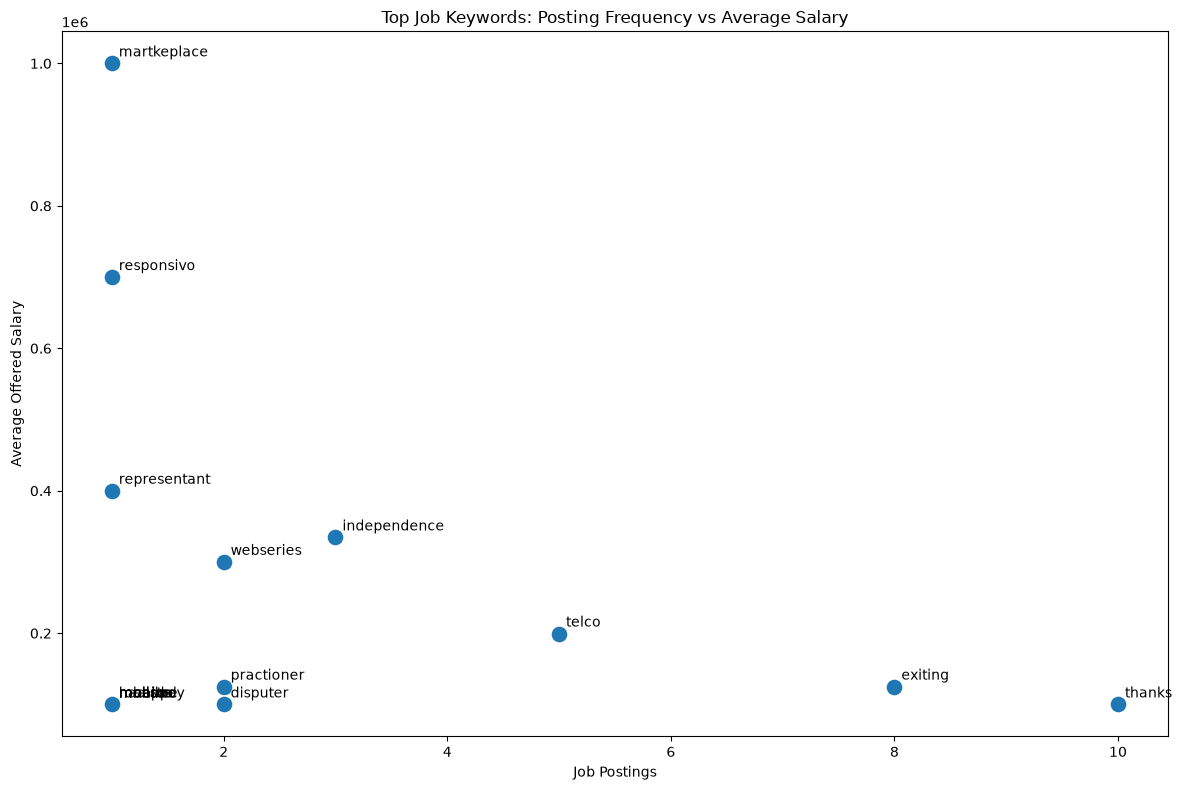

In [97]:
top_15_keywords = keyword_salary_df.head(15).copy()

plt.figure(figsize=(12, 8))

sns.scatterplot(
    data=top_15_keywords,
    x="Job_Postings",
    y="Average_Salary",
    s=150
)

for _, row in top_15_keywords.iterrows():

    plt.annotate(
        row["Keyword"],
        (
            row["Job_Postings"],
            row["Average_Salary"]
        ),
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.title(
    "Top Job Keywords: Posting Frequency vs Average Salary"
)

plt.xlabel("Job Postings")
plt.ylabel("Average Offered Salary")

plt.tight_layout()
plt.show()

In [98]:
correlation_data = keyword_salary_df[
    ["Job_Postings", "Average_Salary"]
].dropna()

pearson_corr = correlation_data[
    "Job_Postings"
].corr(
    correlation_data["Average_Salary"],
    method="pearson"
)

spearman_corr = correlation_data[
    "Job_Postings"
].corr(
    correlation_data["Average_Salary"],
    method="spearman"
)

print("Pearson Correlation :", round(pearson_corr, 4))
print("Spearman Correlation:", round(spearman_corr, 4))

Pearson Correlation : -0.0005
Spearman Correlation: 0.3949


In [99]:
pearson_r, pearson_p = pearsonr(
    correlation_data["Job_Postings"],
    correlation_data["Average_Salary"]
)

print("Pearson r :", round(pearson_r, 4))
print("p-value   :", round(pearson_p, 4))

Pearson r : -0.0005
p-value   : 0.9258


In [100]:
spearman_r, spearman_p = spearmanr(
    correlation_data["Job_Postings"],
    correlation_data["Average_Salary"]
)

print("Spearman r :", round(spearman_r, 4))
print("p-value    :", round(spearman_p, 4))

Spearman r : 0.3949
p-value    : 0.0


In [101]:
selected_keyword = keyword_salary_df.iloc[0]["Keyword"]

keyword_jobs = salary_df[
    salary_df["clean_job_title"].str.contains(
        rf"\b{re.escape(selected_keyword)}\b",
        case=False,
        regex=True,
        na=False
    )
]

print("Selected Keyword:", selected_keyword)
print("Number of Jobs:", len(keyword_jobs))

print("\nSalary Statistics:")
print(
    keyword_jobs["offered_salary"].describe()
)

Selected Keyword: martkeplace
Number of Jobs: 0

Salary Statistics:
count    0.0
mean     NaN
std      NaN
min      NaN
25%      NaN
50%      NaN
75%      NaN
max      NaN
Name: offered_salary, dtype: float64


In [102]:
selected_keyword = keyword_salary_df.iloc[0]["Keyword"]

keyword_jobs = salary_df[
    salary_df["clean_job_title"].str.contains(
        rf"\b{re.escape(selected_keyword)}\b",
        case=False,
        regex=True,
        na=False
    )
]

print("Selected Keyword:", selected_keyword)
print("Number of Jobs:", len(keyword_jobs))

print("\nSalary Statistics:")
print(
    keyword_jobs["offered_salary"].describe()
)

Selected Keyword: martkeplace
Number of Jobs: 0

Salary Statistics:
count    0.0
mean     NaN
std      NaN
min      NaN
25%      NaN
50%      NaN
75%      NaN
max      NaN
Name: offered_salary, dtype: float64


In [103]:
task1_summary = pd.DataFrame({
    "Metric": [
        "Total Jobs",
        "Jobs with Salary Data",
        "Missing Salary Records",
        "Unique Job Title Keywords",
        "Keywords Analyzed"
    ],
    
    "Value": [
        len(df),
        salary_df["offered_salary"].notna().sum(),
        df["offered_salary"].isna().sum(),
        len(keyword_counter),
        len(keyword_salary_df)
    ]
})

task1_summary

,Metric,Value
0,Total Jobs,244828
1,Jobs with Salary Data,0
2,Missing Salary Records,38515
3,Unique Job Title Keywords,0
4,Keywords Analyzed,31477


In [104]:
highest_avg_salary_keyword = (
    keyword_salary_df
    .loc[
        keyword_salary_df["Average_Salary"].idxmax()
    ]
)

most_frequent_keyword = (
    keyword_salary_df
    .loc[
        keyword_salary_df["Job_Postings"].idxmax()
    ]
)

print("=" * 70)
print("TASK 1 - KEY FINDINGS")
print("=" * 70)

print(
    "Highest average salary keyword:",
    highest_avg_salary_keyword["Keyword"]
)

print(
    "Average salary:",
    round(
        highest_avg_salary_keyword["Average_Salary"],
        2
    )
)

print(
    "Most frequently occurring keyword:",
    most_frequent_keyword["Keyword"]
)

print(
    "Number of postings:",
    int(most_frequent_keyword["Job_Postings"])
)

print(
    "Pearson correlation:",
    round(pearson_r, 4)
)

print(
    "Spearman correlation:",
    round(spearman_r, 4)
)

print("=" * 70)

TASK 1 - KEY FINDINGS
Highest average salary keyword: martkeplace
Average salary: 1000000.0
Most frequently occurring keyword: needed
Number of postings: 14657
Pearson correlation: -0.0005
Spearman correlation: 0.3949


In [105]:
CLEANED_DATA_PATH = "../data/cleaned_job_market_data.csv"

df = pd.read_csv(CLEANED_DATA_PATH)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (244828, 8)


In [106]:
CLEANED_DATA_PATH = "../data/cleaned_job_market_data.csv"

df = pd.read_csv(CLEANED_DATA_PATH)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (244828, 8)


In [107]:
possible_title_columns = [
    col for col in df.columns
    if any(
        keyword in col.lower()
        for keyword in [
            "title",
            "job_title",
            "jobtitle"
        ]
    )
]

print("Possible Job Title Columns:")
print(possible_title_columns)

Possible Job Title Columns:
['title']


In [108]:
possible_title_columns = [
    col for col in df.columns
    if any(
        keyword in col.lower()
        for keyword in [
            "title",
            "job_title",
            "jobtitle"
        ]
    )
]

print("Possible Job Title Columns:")
print(possible_title_columns)

Possible Job Title Columns:
['title']


In [109]:
possible_date_columns = [
    col for col in df.columns
    if any(
        keyword in col.lower()
        for keyword in [
            "date",
            "posted",
            "created",
            "time"
        ]
    )
]

print("Possible Date Columns:")
print(possible_date_columns)

Possible Date Columns:
['published_date']


In [110]:
DATE_COLUMN = possible_date_columns[0]

print("Selected Date Column:", DATE_COLUMN)

Selected Date Column: published_date


In [111]:
df[DATE_COLUMN] = pd.to_datetime(
    df[DATE_COLUMN],
    errors="coerce"
)

print(df[DATE_COLUMN].dtype)

datetime64[us, UTC]


In [112]:
print("Valid dates:", df[DATE_COLUMN].notna().sum())
print("Missing dates:", df[DATE_COLUMN].isna().sum())

Valid dates: 244828
Missing dates: 0


In [113]:
print("Valid dates:", df[DATE_COLUMN].notna().sum())
print("Missing dates:", df[DATE_COLUMN].isna().sum())

Valid dates: 244828
Missing dates: 0


In [114]:
print("Minimum Posting Date:")
print(df[DATE_COLUMN].min())

print("\nMaximum Posting Date:")
print(df[DATE_COLUMN].max())

Minimum Posting Date:
2023-11-02 09:22:02+00:00

Maximum Posting Date:
2024-03-24 14:16:47+00:00


In [115]:
df["clean_job_title"] = (
    df[JOB_TITLE_COLUMN]
    .astype(str)
    .str.lower()
    .str.strip()
)

In [116]:
job_frequency = (
    df["clean_job_title"]
    .value_counts()
    .reset_index()
)

job_frequency.columns = [
    "Job_Title",
    "Posting_Count"
]

job_frequency.head(20)

,Job_Title,Posting_Count
0,social media manager,509
1,logo design,490
2,video editor,413
3,virtual assistant,408
4,graphic designer,367
5,youtube video editor,181
6,lead generation,176
7,full stack developer,172
8,logo designer,171
9,data entry,169


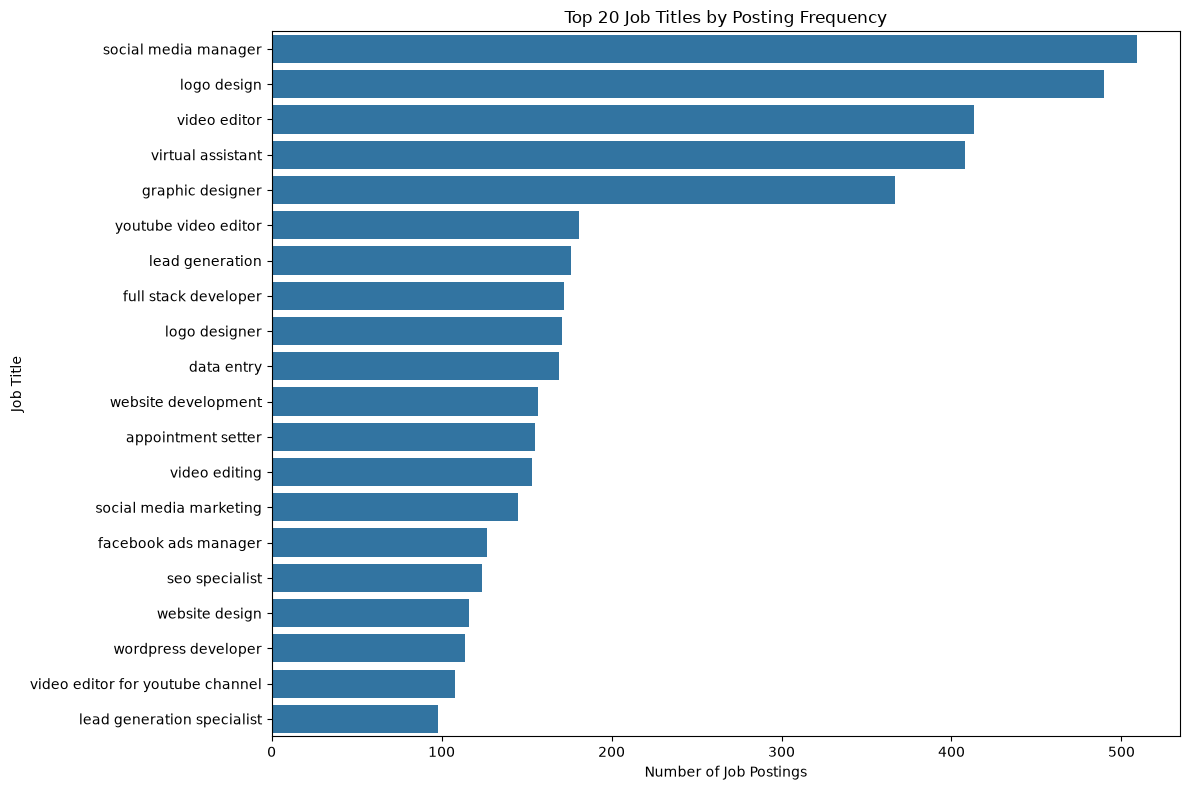

In [117]:
top_20_jobs = job_frequency.head(20)

plt.figure(figsize=(12, 8))

sns.barplot(
    data=top_20_jobs,
    x="Posting_Count",
    y="Job_Title"
)

plt.title("Top 20 Job Titles by Posting Frequency")
plt.xlabel("Number of Job Postings")
plt.ylabel("Job Title")

plt.tight_layout()
plt.show()

In [118]:
def categorize_job(title):

    title = str(title).lower()

    if any(word in title for word in [
        "data scientist",
        "data science",
        "data analyst",
        "data analysis",
        "data engineer",
        "data engineering",
        "analytics"
    ]):
        return "Data & Analytics"

    elif any(word in title for word in [
        "machine learning",
        "artificial intelligence",
        "deep learning",
        "ai ",
        " ml "
    ]):
        return "AI & Machine Learning"

    elif any(word in title for word in [
        "python",
        "java",
        "software developer",
        "software engineer",
        "programmer",
        "developer"
    ]):
        return "Software Development"

    elif any(word in title for word in [
        "web developer",
        "web development",
        "wordpress",
        "shopify",
        "frontend",
        "front-end",
        "backend",
        "back-end"
    ]):
        return "Web Development"

    elif any(word in title for word in [
        "marketing",
        "seo",
        "digital marketing",
        "social media",
        "advertising"
    ]):
        return "Marketing"

    elif any(word in title for word in [
        "graphic design",
        "designer",
        "ui design",
        "ux design",
        "logo design"
    ]):
        return "Design"

    elif any(word in title for word in [
        "writer",
        "writing",
        "content",
        "copywriter",
        "copywriting"
    ]):
        return "Writing & Content"

    elif any(word in title for word in [
        "accountant",
        "accounting",
        "finance",
        "financial",
        "bookkeeping"
    ]):
        return "Finance & Accounting"

    elif any(word in title for word in [
        "sales",
        "business development",
        "lead generation"
    ]):
        return "Sales & Business Development"

    elif any(word in title for word in [
        "customer service",
        "customer support",
        "virtual assistant",
        "administrative"
    ]):
        return "Customer Support & Admin"

    elif any(word in title for word in [
        "engineer",
        "engineering",
        "mechanical",
        "electrical",
        "civil"
    ]):
        return "Engineering"

    else:
        return "Other"

In [119]:
df["job_category"] = df["clean_job_title"].apply(
    categorize_job
)

df[
    [JOB_TITLE_COLUMN, "job_category"]
].head(20)

,title,job_category
0,Experienced Media Buyer For Solar Pannel and R...,Other
1,Full Stack Developer,Software Development
2,SMMA Bubble App,Other
3,Talent Hunter Specialized in Marketing,Marketing
4,Data Engineer,Data & Analytics
5,SEO for Portuguese Psychologist site,Marketing
6,Want to fix the WordPress Plugin,Web Development
7,need Portuguese writers who can understand and...,Writing & Content
8,Looker Studio Dashboard for Leadgen and E-Comm...,Other
9,PHP/HTML/CSS WordPress Developer Needed for We...,Software Development


In [120]:
category_frequency = (
    df["job_category"]
    .value_counts()
    .reset_index()
)

category_frequency.columns = [
    "Job_Category",
    "Posting_Count"
]

category_frequency

,Job_Category,Posting_Count
0,Other,150112
1,Marketing,18501
2,Software Development,18157
3,Design,14027
4,Writing & Content,11570
5,Web Development,10575
6,Sales & Business Development,6624
7,AI & Machine Learning,4161
8,Customer Support & Admin,4011
9,Finance & Accounting,2896


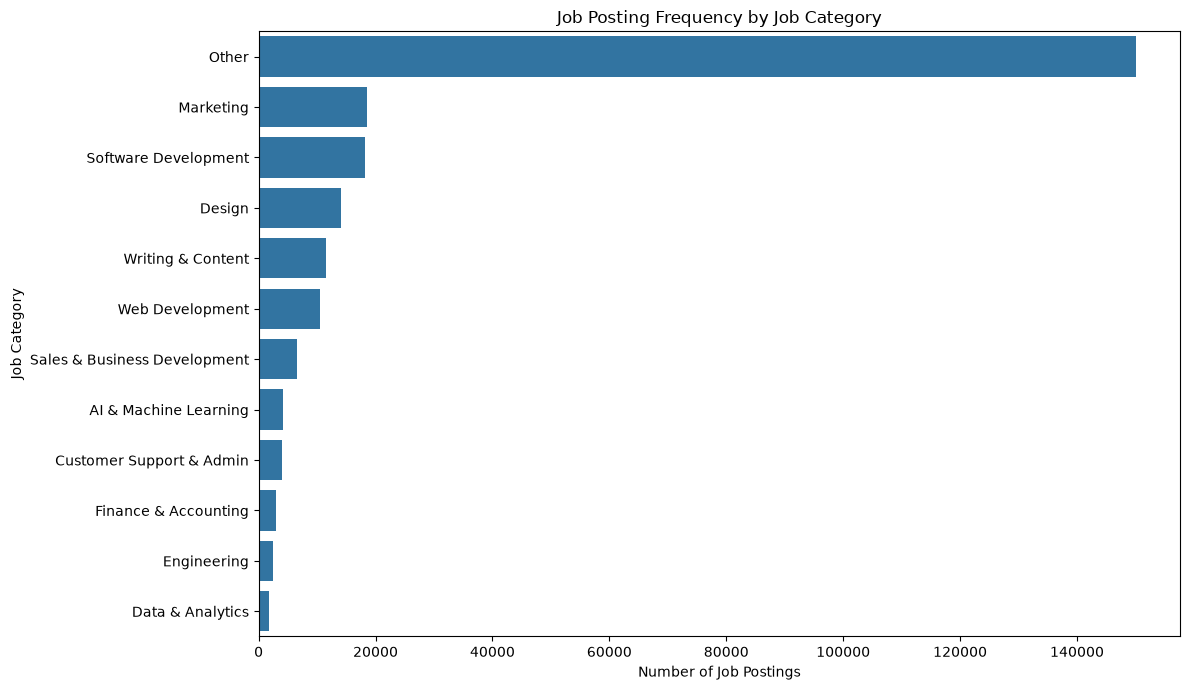

In [121]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=category_frequency,
    x="Posting_Count",
    y="Job_Category"
)

plt.title("Job Posting Frequency by Job Category")
plt.xlabel("Number of Job Postings")
plt.ylabel("Job Category")

plt.tight_layout()
plt.show()

In [122]:
category_frequency["Percentage"] = (
    category_frequency["Posting_Count"]
    / category_frequency["Posting_Count"].sum()
    * 100
)

category_frequency["Percentage"] = (
    category_frequency["Percentage"]
    .round(2)
)

category_frequency

,Job_Category,Posting_Count,Percentage
0,Other,150112,61.31
1,Marketing,18501,7.56
2,Software Development,18157,7.42
3,Design,14027,5.73
4,Writing & Content,11570,4.73
5,Web Development,10575,4.32
6,Sales & Business Development,6624,2.71
7,AI & Machine Learning,4161,1.70
8,Customer Support & Admin,4011,1.64
9,Finance & Accounting,2896,1.18


In [123]:
monthly_category = (
    df.dropna(subset=[DATE_COLUMN])
    .groupby([
        df[DATE_COLUMN].dt.to_period("M"),
        "job_category"
    ])
    .size()
    .reset_index(name="Posting_Count")
)

monthly_category[DATE_COLUMN] = (
    monthly_category[DATE_COLUMN]
    .astype(str)
)

monthly_category.head(20)

,published_date,job_category,Posting_Count
0,2023-11,Other,1
1,2023-12,Data & Analytics,1
2,2023-12,Finance & Accounting,1
3,2023-12,Marketing,1
4,2023-12,Other,4
5,2023-12,Sales & Business Development,1
6,2023-12,Writing & Content,2
7,2024-01,AI & Machine Learning,1
8,2024-01,Customer Support & Admin,10
9,2024-01,Data & Analytics,1


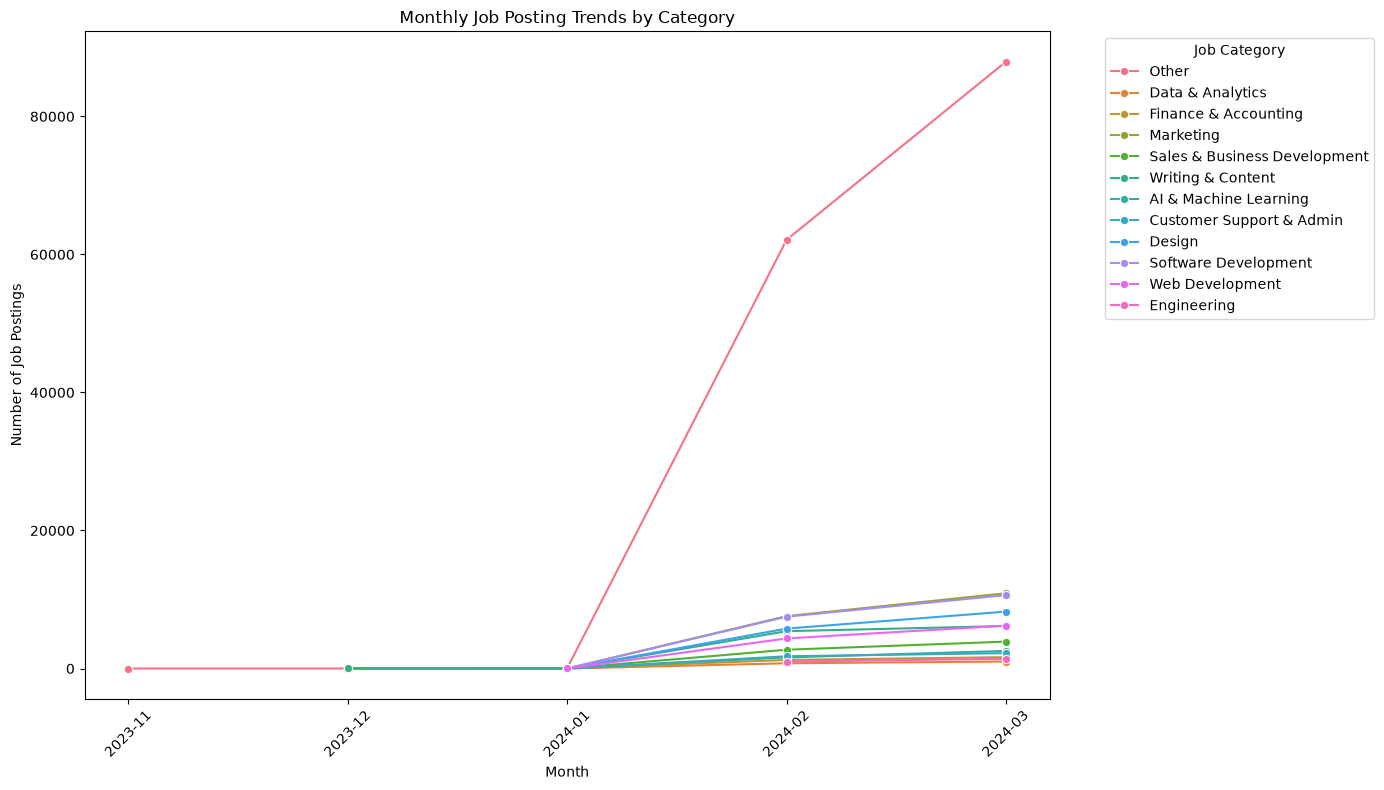

In [124]:
plt.figure(figsize=(14, 8))

sns.lineplot(
    data=monthly_category,
    x=DATE_COLUMN,
    y="Posting_Count",
    hue="job_category",
    marker="o"
)

plt.title("Monthly Job Posting Trends by Category")
plt.xlabel("Month")
plt.ylabel("Number of Job Postings")
plt.xticks(rotation=45)

plt.legend(
    title="Job Category",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

In [125]:
category_monthly_pivot = monthly_category.pivot(
    index=DATE_COLUMN,
    columns="job_category",
    values="Posting_Count"
).fillna(0)

category_monthly_pivot

job_category,AI & Machine Learning,Customer Support & Admin,Data & Analytics,Design,Engineering,Finance & Accounting,Marketing,Other,Sales & Business Development,Software Development,Web Development,Writing & Content
published_date,,,,,,,,,,,,
2023-11,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
2023-12,0.0,0.0,1.0,0.0,0.0,1.0,1.0,4.0,1.0,0.0,0.0,2.0
2024-01,1.0,10.0,1.0,2.0,0.0,5.0,6.0,51.0,7.0,8.0,2.0,3.0
2024-02,1608.0,1774.0,759.0,5785.0,1010.0,1246.0,7587.0,62123.0,2722.0,7508.0,4356.0,5409.0
2024-03,2552.0,2227.0,1014.0,8240.0,1409.0,1644.0,10907.0,87933.0,3894.0,10641.0,6217.0,6156.0


In [126]:
growth_records = []

for category in category_monthly_pivot.columns:

    values = category_monthly_pivot[category]

    first_value = values.iloc[0]
    last_value = values.iloc[-1]

    absolute_growth = last_value - first_value

    if first_value > 0:
        growth_percentage = (
            absolute_growth / first_value
        ) * 100
    else:
        growth_percentage = np.nan

    growth_records.append({
        "Job_Category": category,
        "First_Period_Postings": first_value,
        "Last_Period_Postings": last_value,
        "Absolute_Growth": absolute_growth,
        "Growth_Percentage": growth_percentage
    })

category_growth = pd.DataFrame(growth_records)

category_growth = category_growth.sort_values(
    by="Growth_Percentage",
    ascending=False
)

category_growth

,Job_Category,First_Period_Postings,Last_Period_Postings,Absolute_Growth,Growth_Percentage
7,Other,1.0,87933.0,87932.0,8793200.0
0,AI & Machine Learning,0.0,2552.0,2552.0,NaN
1,Customer Support & Admin,0.0,2227.0,2227.0,NaN
2,Data & Analytics,0.0,1014.0,1014.0,NaN
3,Design,0.0,8240.0,8240.0,NaN
4,Engineering,0.0,1409.0,1409.0,NaN
5,Finance & Accounting,0.0,1644.0,1644.0,NaN
6,Marketing,0.0,10907.0,10907.0,NaN
8,Sales & Business Development,0.0,3894.0,3894.0,NaN
9,Software Development,0.0,10641.0,10641.0,NaN


In [127]:
emerging_categories = category_growth[
    (category_growth["Growth_Percentage"] > 0) &
    (category_growth["Last_Period_Postings"] >= 2)
].copy()

emerging_categories = emerging_categories.sort_values(
    by="Growth_Percentage",
    ascending=False
)

emerging_categories

,Job_Category,First_Period_Postings,Last_Period_Postings,Absolute_Growth,Growth_Percentage
7,Other,1.0,87933.0,87932.0,8793200.0


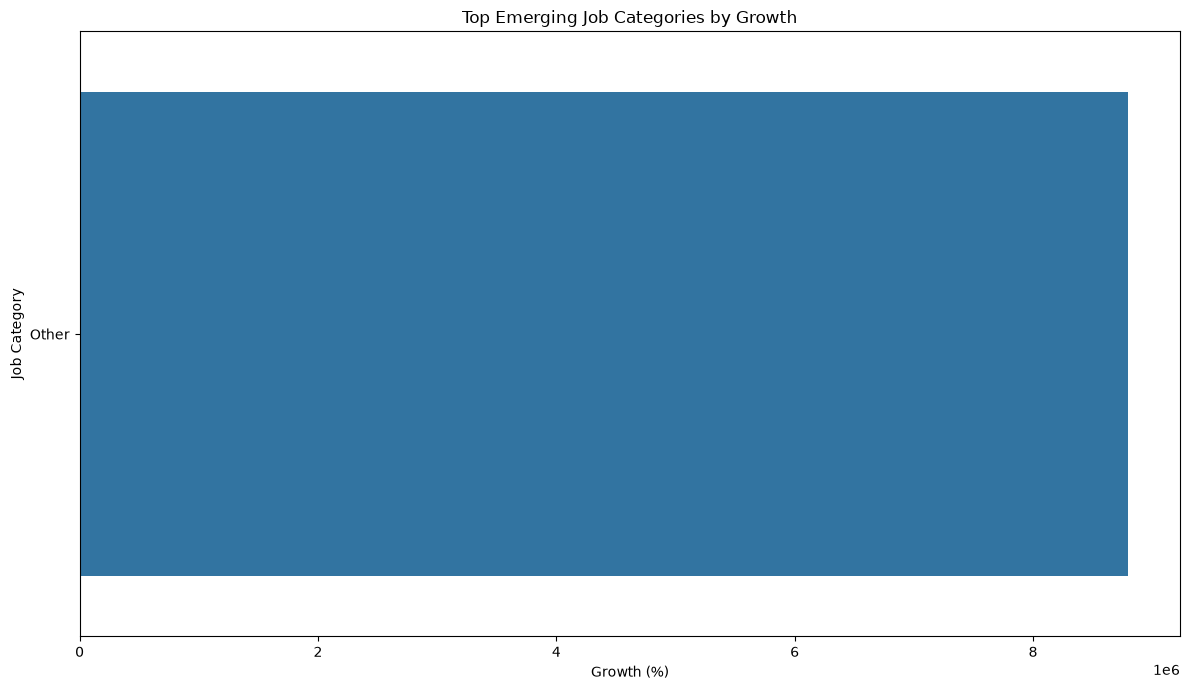

In [128]:
top_emerging = emerging_categories.head(10)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_emerging,
    x="Growth_Percentage",
    y="Job_Category"
)

plt.title("Top Emerging Job Categories by Growth")
plt.xlabel("Growth (%)")
plt.ylabel("Job Category")

plt.tight_layout()
plt.show()

In [129]:
category_analysis = category_frequency.merge(
    category_growth,
    on="Job_Category",
    how="left"
)

category_analysis = category_analysis.sort_values(
    by="Posting_Count",
    ascending=False
)

category_analysis

,Job_Category,Posting_Count,Percentage,First_Period_Postings,Last_Period_Postings,Absolute_Growth,Growth_Percentage
0,Other,150112,61.31,1.0,87933.0,87932.0,8793200.0
1,Marketing,18501,7.56,0.0,10907.0,10907.0,NaN
2,Software Development,18157,7.42,0.0,10641.0,10641.0,NaN
3,Design,14027,5.73,0.0,8240.0,8240.0,NaN
4,Writing & Content,11570,4.73,0.0,6156.0,6156.0,NaN
5,Web Development,10575,4.32,0.0,6217.0,6217.0,NaN
6,Sales & Business Development,6624,2.71,0.0,3894.0,3894.0,NaN
7,AI & Machine Learning,4161,1.70,0.0,2552.0,2552.0,NaN
8,Customer Support & Admin,4011,1.64,0.0,2227.0,2227.0,NaN
9,Finance & Accounting,2896,1.18,0.0,1644.0,1644.0,NaN


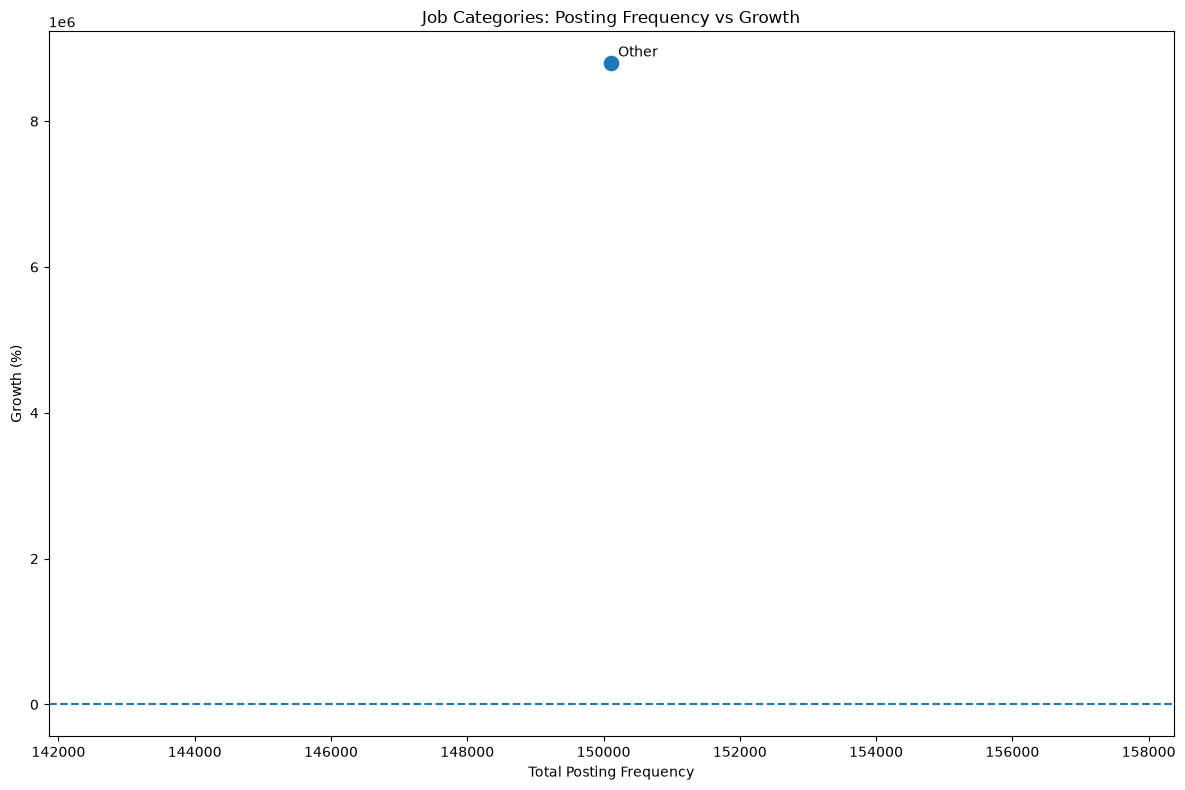

In [130]:
plt.figure(figsize=(12, 8))

sns.scatterplot(
    data=category_analysis,
    x="Posting_Count",
    y="Growth_Percentage",
    s=150
)

for _, row in category_analysis.iterrows():

    if pd.notna(row["Growth_Percentage"]):

        plt.annotate(
            row["Job_Category"],
            (
                row["Posting_Count"],
                row["Growth_Percentage"]
            ),
            xytext=(5, 5),
            textcoords="offset points"
        )

plt.axhline(
    0,
    linestyle="--"
)

plt.title(
    "Job Categories: Posting Frequency vs Growth"
)

plt.xlabel("Total Posting Frequency")
plt.ylabel("Growth (%)")

plt.tight_layout()
plt.show()

In [131]:
if len(emerging_categories) > 0:

    top_emerging_category = (
        emerging_categories.iloc[0]
    )

    print("Top Emerging Category:")
    print(
        top_emerging_category[
            [
                "Job_Category",
                "First_Period_Postings",
                "Last_Period_Postings",
                "Absolute_Growth",
                "Growth_Percentage"
            ]
        ]
    )

else:

    print(
        "No category satisfied the selected "
        "emerging-category criteria."
    )

Top Emerging Category:
Job_Category                 Other
First_Period_Postings          1.0
Last_Period_Postings       87933.0
Absolute_Growth            87932.0
Growth_Percentage        8793200.0
Name: 7, dtype: object


In [132]:
TASK2_OUTPUT = "../reports/task2_emerging_job_categories.csv"

category_analysis.to_csv(
    TASK2_OUTPUT,
    index=False
)

print("Task 2 result saved successfully!")
print(TASK2_OUTPUT)

Task 2 result saved successfully!
../reports/task2_emerging_job_categories.csv


In [133]:
MONTHLY_OUTPUT = "../reports/monthly_job_category_trends.csv"

monthly_category.to_csv(
    MONTHLY_OUTPUT,
    index=False
)

print("Monthly trend data saved successfully!")

Monthly trend data saved successfully!


In [134]:
UPDATED_DATA_PATH = "../data/cleaned_job_market_data_v2.csv"

df.to_csv(
    UPDATED_DATA_PATH,
    index=False
)

print("Updated dataset saved:")
print(UPDATED_DATA_PATH)

Updated dataset saved:
../data/cleaned_job_market_data_v2.csv


In [135]:
print("=" * 70)
print("TASK 2 - EMERGING JOB CATEGORIES SUMMARY")
print("=" * 70)

print("Total Jobs:", len(df))

print(
    "Number of Job Categories:",
    df["job_category"].nunique()
)

print(
    "Number of Emerging Categories:",
    len(emerging_categories)
)

if len(emerging_categories) > 0:

    print(
        "\nTop Emerging Categories:"
    )

    print(
        emerging_categories[
            [
                "Job_Category",
                "Growth_Percentage"
            ]
        ].head(10).to_string(index=False)
    )

print("=" * 70)

TASK 2 - EMERGING JOB CATEGORIES SUMMARY
Total Jobs: 244828
Number of Job Categories: 12
Number of Emerging Categories: 1

Top Emerging Categories:
Job_Category  Growth_Percentage
       Other          8793200.0


In [136]:
# ============================================
# STEP 6 - HIGH DEMAND JOB ROLE PREDICTION
# ============================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import joblib
import os

print("Libraries imported successfully!")

Libraries imported successfully!


In [137]:
DATA_PATH = "../data/cleaned_job_market_data_v2.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

df.head()

Dataset loaded successfully!
Rows: 244828
Columns: 10


,title,link,published_date,is_hourly,hourly_low,hourly_high,budget,country,clean_job_title,job_category
0,Experienced Media Buyer For Solar Pannel and R...,https://www.upwork.com/jobs/Experienced-Media-...,2024-02-17 09:09:54+00:00,False,NaN,NaN,500.0,NaN,experienced media buyer for solar pannel and r...,Other
1,Full Stack Developer,https://www.upwork.com/jobs/Full-Stack-Develop...,2024-02-17 09:09:17+00:00,False,NaN,NaN,1100.0,United States,full stack developer,Software Development
2,SMMA Bubble App,https://www.upwork.com/jobs/SMMA-Bubble-App_%7...,2024-02-17 09:08:46+00:00,True,10.0,30.0,NaN,United States,smma bubble app,Other
3,Talent Hunter Specialized in Marketing,https://www.upwork.com/jobs/Talent-Hunter-Spec...,2024-02-17 09:08:08+00:00,True,NaN,NaN,NaN,United States,talent hunter specialized in marketing,Marketing
4,Data Engineer,https://www.upwork.com/jobs/Data-Engineer_%7E0...,2024-02-17 09:07:42+00:00,False,NaN,NaN,650.0,India,data engineer,Data & Analytics


In [138]:
DATA_PATH = "../data/cleaned_job_market_data.csv"

df = pd.read_csv(DATA_PATH)

print(df.shape)

(244828, 8)


In [139]:
print("Available columns:")
print(df.columns.tolist())

Available columns:
['title', 'link', 'published_date', 'is_hourly', 'hourly_low', 'hourly_high', 'budget', 'country']


In [140]:
# Use the dataset that already includes the job_category column
df = pd.read_csv(UPDATED_DATA_PATH)

if "job_category" not in df.columns:
    df["clean_job_title"] = (
        df["title"].fillna("").astype(str).str.lower().str.strip()
    )

    def categorize_job(title):
        title = str(title).lower()

        if any(word in title for word in [
            "data scientist", "data science", "data analyst", "data analysis",
            "data engineer", "data engineering", "analytics"
        ]):
            return "Data & Analytics"

        elif any(word in title for word in [
            "machine learning", "artificial intelligence", "deep learning",
            "ai ", " ml "
        ]):
            return "AI & Machine Learning"

        elif any(word in title for word in [
            "python", "java", "software developer", "software engineer",
            "programmer", "developer"
        ]):
            return "Software Development"

        elif any(word in title for word in [
            "web developer", "web development", "wordpress", "shopify",
            "frontend", "front-end", "backend", "back-end"
        ]):
            return "Web Development"

        elif any(word in title for word in [
            "marketing", "seo", "digital marketing", "social media",
            "advertising"
        ]):
            return "Marketing"

        elif any(word in title for word in [
            "graphic design", "designer", "ui design", "ux design",
            "logo design"
        ]):
            return "Design"

        elif any(word in title for word in [
            "writer", "writing", "content", "copywriter", "copywriting"
        ]):
            return "Writing & Content"

        elif any(word in title for word in [
            "accountant", "accounting", "finance", "financial",
            "bookkeeping"
        ]):
            return "Finance & Accounting"

        elif any(word in title for word in [
            "sales", "business development", "lead generation"
        ]):
            return "Sales & Business Development"

        elif any(word in title for word in [
            "customer service", "customer support", "virtual assistant",
            "administrative"
        ]):
            return "Customer Support & Admin"

        elif any(word in title for word in [
            "engineer", "engineering", "mechanical", "electrical", "civil"
        ]):
            return "Engineering"

        return "Other"

    df["job_category"] = df["clean_job_title"].apply(categorize_job)

print(df["job_category"].value_counts())

job_category
Other                           150112
Marketing                        18501
Software Development             18157
Design                           14027
Writing & Content                11570
Web Development                  10575
Sales & Business Development      6624
AI & Machine Learning             4161
Customer Support & Admin          4011
Finance & Accounting              2896
Engineering                       2419
Data & Analytics                  1775
Name: count, dtype: int64


In [141]:
possible_date_columns = [
    col for col in df.columns
    if any(keyword in col.lower()
           for keyword in ["date", "posted", "created", "time"])
]

print("Possible date columns:")
print(possible_date_columns)

Possible date columns:
['published_date']


In [142]:
DATE_COLUMN = "published_date"

In [143]:
DATE_COLUMN = "date"

In [144]:
# Resolve the actual date column before converting it
if DATE_COLUMN not in df.columns:
    date_candidates = [
        col for col in df.columns
        if any(keyword in col.lower() for keyword in ["date", "posted", "created", "time"])
    ]
    if not date_candidates:
        raise KeyError("No date-like column found in the dataframe.")
    DATE_COLUMN = date_candidates[0]

# Convert only if the resolved column exists
if DATE_COLUMN in df.columns:
    df[DATE_COLUMN] = pd.to_datetime(df[DATE_COLUMN], errors="coerce")
else:
    raise KeyError(f"Column '{DATE_COLUMN}' not found in dataframe.")

print(df[DATE_COLUMN].dtype)

datetime64[us, UTC]


In [145]:
print("Invalid dates:", df[DATE_COLUMN].isna().sum())

Invalid dates: 0


In [146]:
daily_category = (
    df.dropna(subset=[DATE_COLUMN, "job_category"])
      .groupby([
          df[DATE_COLUMN].dt.floor("D"),
          "job_category"
      ])
      .size()
      .reset_index(name="posting_count")
)

daily_category.columns = [
    "date",
    "job_category",
    "posting_count"
]

daily_category.head()

,date,job_category,posting_count
0,2023-11-02 00:00:00+00:00,Other,1
1,2023-12-02 00:00:00+00:00,Other,1
2,2023-12-05 00:00:00+00:00,Sales & Business Development,1
3,2023-12-11 00:00:00+00:00,Writing & Content,1
4,2023-12-13 00:00:00+00:00,Other,1


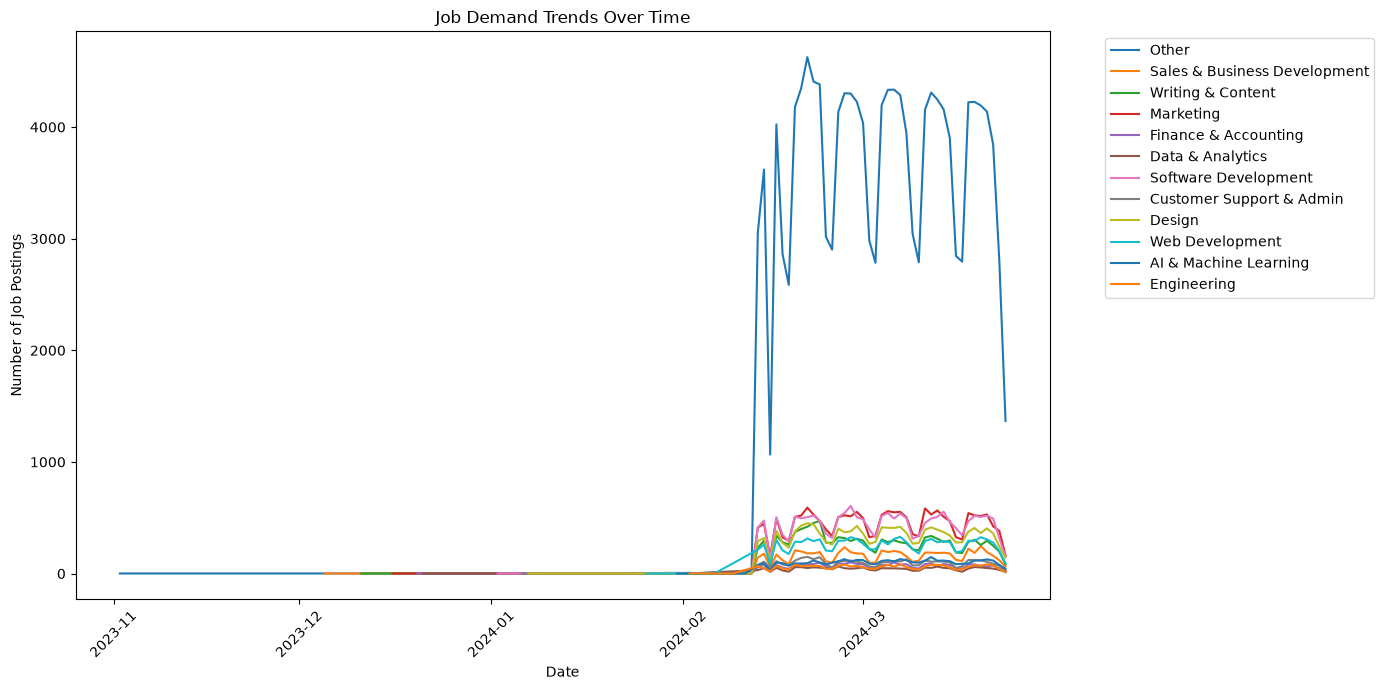

In [147]:
plt.figure(figsize=(14, 7))

for category in daily_category["job_category"].unique():

    temp = daily_category[
        daily_category["job_category"] == category
    ]

    plt.plot(
        temp["date"],
        temp["posting_count"],
        label=category
    )

plt.title("Job Demand Trends Over Time")
plt.xlabel("Date")
plt.ylabel("Number of Job Postings")
plt.xticks(rotation=45)
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

In [148]:
all_dates = pd.date_range(
    daily_category["date"].min(),
    daily_category["date"].max(),
    freq="D"
)

all_categories = daily_category["job_category"].unique()

complete_index = pd.MultiIndex.from_product(
    [all_dates, all_categories],
    names=["date", "job_category"]
)

daily_category = (
    daily_category
    .set_index(["date", "job_category"])
    .reindex(complete_index, fill_value=0)
    .reset_index()
)

daily_category.head()

,date,job_category,posting_count
0,2023-11-02 00:00:00+00:00,Other,1
1,2023-11-02 00:00:00+00:00,Sales & Business Development,0
2,2023-11-02 00:00:00+00:00,Writing & Content,0
3,2023-11-02 00:00:00+00:00,Marketing,0
4,2023-11-02 00:00:00+00:00,Finance & Accounting,0


In [149]:
daily_category = daily_category.sort_values(
    ["job_category", "date"]
)

daily_category["lag_1"] = (
    daily_category
    .groupby("job_category")["posting_count"]
    .shift(1)
)

daily_category["lag_3"] = (
    daily_category
    .groupby("job_category")["posting_count"]
    .shift(3)
)

daily_category["lag_7"] = (
    daily_category
    .groupby("job_category")["posting_count"]
    .shift(7)
)

In [150]:
daily_category["rolling_mean_7"] = (
    daily_category
    .groupby("job_category")["posting_count"]
    .transform(
        lambda x: x.shift(1).rolling(7).mean()
    )
)

daily_category["rolling_std_7"] = (
    daily_category
    .groupby("job_category")["posting_count"]
    .transform(
        lambda x: x.shift(1).rolling(7).std()
    )
)

In [151]:
daily_category["next_day_demand"] = (
    daily_category
    .groupby("job_category")["posting_count"]
    .shift(-1)
)

In [152]:
daily_category[
    [
        "date",
        "job_category",
        "posting_count",
        "lag_1",
        "lag_3",
        "lag_7",
        "rolling_mean_7",
        "next_day_demand"
    ]
].head(20)

,date,job_category,posting_count,lag_1,lag_3,lag_7,rolling_mean_7,next_day_demand
10,2023-11-02 00:00:00+00:00,AI & Machine Learning,0,NaN,NaN,NaN,NaN,0.0
22,2023-11-03 00:00:00+00:00,AI & Machine Learning,0,0.0,NaN,NaN,NaN,0.0
34,2023-11-04 00:00:00+00:00,AI & Machine Learning,0,0.0,NaN,NaN,NaN,0.0
46,2023-11-05 00:00:00+00:00,AI & Machine Learning,0,0.0,0.0,NaN,NaN,0.0
58,2023-11-06 00:00:00+00:00,AI & Machine Learning,0,0.0,0.0,NaN,NaN,0.0
70,2023-11-07 00:00:00+00:00,AI & Machine Learning,0,0.0,0.0,NaN,NaN,0.0
82,2023-11-08 00:00:00+00:00,AI & Machine Learning,0,0.0,0.0,NaN,NaN,0.0
94,2023-11-09 00:00:00+00:00,AI & Machine Learning,0,0.0,0.0,0.0,0.0,0.0
106,2023-11-10 00:00:00+00:00,AI & Machine Learning,0,0.0,0.0,0.0,0.0,0.0
118,2023-11-11 00:00:00+00:00,AI & Machine Learning,0,0.0,0.0,0.0,0.0,0.0


In [153]:
category_thresholds = (
    daily_category
    .groupby("job_category")["posting_count"]
    .median()
    .to_dict()
)

print("Category demand thresholds:")

for category, threshold in category_thresholds.items():
    print(category, ":", threshold)

Category demand thresholds:
AI & Machine Learning : 0.0
Customer Support & Admin : 0.0
Data & Analytics : 0.0
Design : 0.0
Engineering : 0.0
Finance & Accounting : 0.0
Marketing : 0.0
Other : 1.0
Sales & Business Development : 0.0
Software Development : 0.0
Web Development : 0.0
Writing & Content : 0.0


In [154]:
daily_category["high_demand"] = daily_category.apply(
    lambda row:
        1
        if row["next_day_demand"] > category_thresholds[row["job_category"]]
        else 0,
    axis=1
)

In [155]:
model_data = daily_category.dropna().copy()

print("Original rows:", len(daily_category))
print("Model rows:", len(model_data))

Original rows: 1728
Model rows: 1632


In [156]:
features = [
    "lag_1",
    "lag_3",
    "lag_7",
    "rolling_mean_7",
    "rolling_std_7"
]

X = model_data[features]
y = model_data["high_demand"]

print("Features:")
print(X.head())

print("\nTarget:")
print(y.head())

Features:
     lag_1  lag_3  lag_7  rolling_mean_7  rolling_std_7
94     0.0    0.0    0.0             0.0            0.0
106    0.0    0.0    0.0             0.0            0.0
118    0.0    0.0    0.0             0.0            0.0
130    0.0    0.0    0.0             0.0            0.0
142    0.0    0.0    0.0             0.0            0.0

Target:
94     0
106    0
118    0
130    0
142    0
Name: high_demand, dtype: int64


In [157]:
model_data = model_data.sort_values("date")

split_index = int(len(model_data) * 0.80)

train_data = model_data.iloc[:split_index]
test_data = model_data.iloc[split_index:]

print("Training rows:", len(train_data))
print("Testing rows:", len(test_data))

Training rows: 1305
Testing rows: 327


In [158]:
X_train = train_data[features]
y_train = train_data["high_demand"]

X_test = test_data[features]
y_test = test_data["high_demand"]

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

X_train: (1305, 5)
X_test: (327, 5)


In [159]:
rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced"
)

rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [160]:
y_pred = rf_model.predict(X_test)

print("Predictions generated successfully!")

Predictions generated successfully!


In [161]:
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", round(accuracy, 4))

Accuracy: 1.0


In [162]:
precision = precision_score(
    y_test,
    y_pred,
    zero_division=0
)

print("Precision:", round(precision, 4))

Precision: 1.0


In [163]:
recall = recall_score(
    y_test,
    y_pred,
    zero_division=0
)

print("Recall:", round(recall, 4))

Recall: 1.0


In [164]:
f1 = f1_score(
    y_test,
    y_pred,
    zero_division=0
)

print("F1 Score:", round(f1, 4))

F1 Score: 1.0


In [165]:
labels = sorted(np.unique(y_test))
target_names = [str(label) for label in labels]

print(
    classification_report(
        y_test,
        y_pred,
        labels=labels,
        target_names=target_names,
        zero_division=0
    )
)

              precision    recall  f1-score   support

           1       1.00      1.00      1.00       327

    accuracy                           1.00       327
   macro avg       1.00      1.00      1.00       327
weighted avg       1.00      1.00      1.00       327



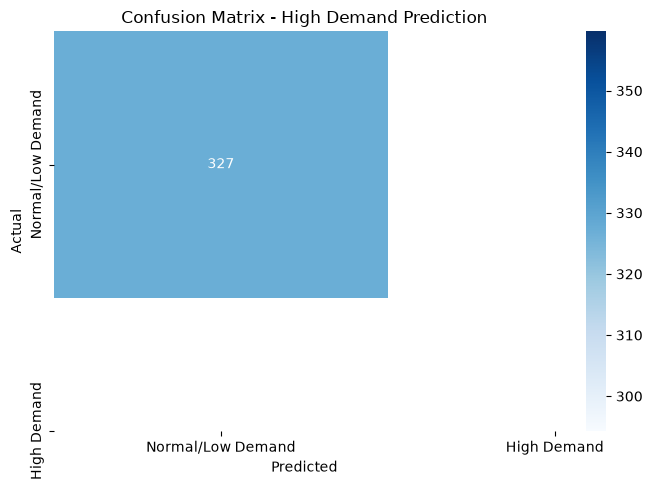

In [166]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "Normal/Low Demand",
        "High Demand"
    ],
    yticklabels=[
        "Normal/Low Demand",
        "High Demand"
    ]
)

plt.title("Confusion Matrix - High Demand Prediction")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

In [167]:
feature_importance = pd.DataFrame({
    "Feature": features,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    "Importance",
    ascending=False
)

print(feature_importance)

          Feature  Importance
4   rolling_std_7    0.402668
3  rolling_mean_7    0.330688
0           lag_1    0.157209
1           lag_3    0.081382
2           lag_7    0.028053


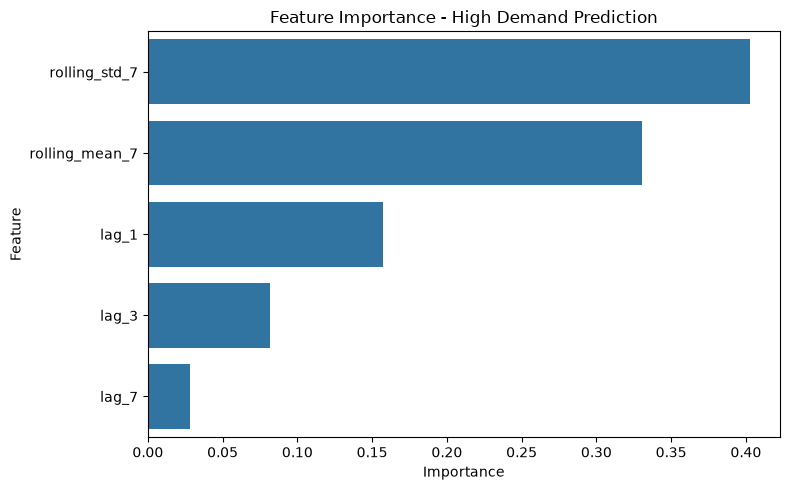

In [168]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)

plt.title("Feature Importance - High Demand Prediction")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [169]:
results = test_data[
    [
        "date",
        "job_category",
        "posting_count",
        "next_day_demand",
        "high_demand"
    ]
].copy()

results["predicted_high_demand"] = y_pred

results.head(20)

,date,job_category,posting_count,next_day_demand,high_demand,predicted_high_demand
1385,2024-02-25 00:00:00+00:00,Data & Analytics,39,64.0,1,1
1389,2024-02-25 00:00:00+00:00,Web Development,200,295.0,1,1
1383,2024-02-25 00:00:00+00:00,Marketing,337,506.0,1,1
1398,2024-02-26 00:00:00+00:00,Software Development,505,542.0,1,1
1396,2024-02-26 00:00:00+00:00,Finance & Accounting,93,87.0,1,1
1402,2024-02-26 00:00:00+00:00,AI & Machine Learning,110,129.0,1,1
1400,2024-02-26 00:00:00+00:00,Design,402,371.0,1,1
1397,2024-02-26 00:00:00+00:00,Data & Analytics,64,48.0,1,1
1393,2024-02-26 00:00:00+00:00,Sales & Business Development,185,236.0,1,1
1394,2024-02-26 00:00:00+00:00,Writing & Content,326,318.0,1,1


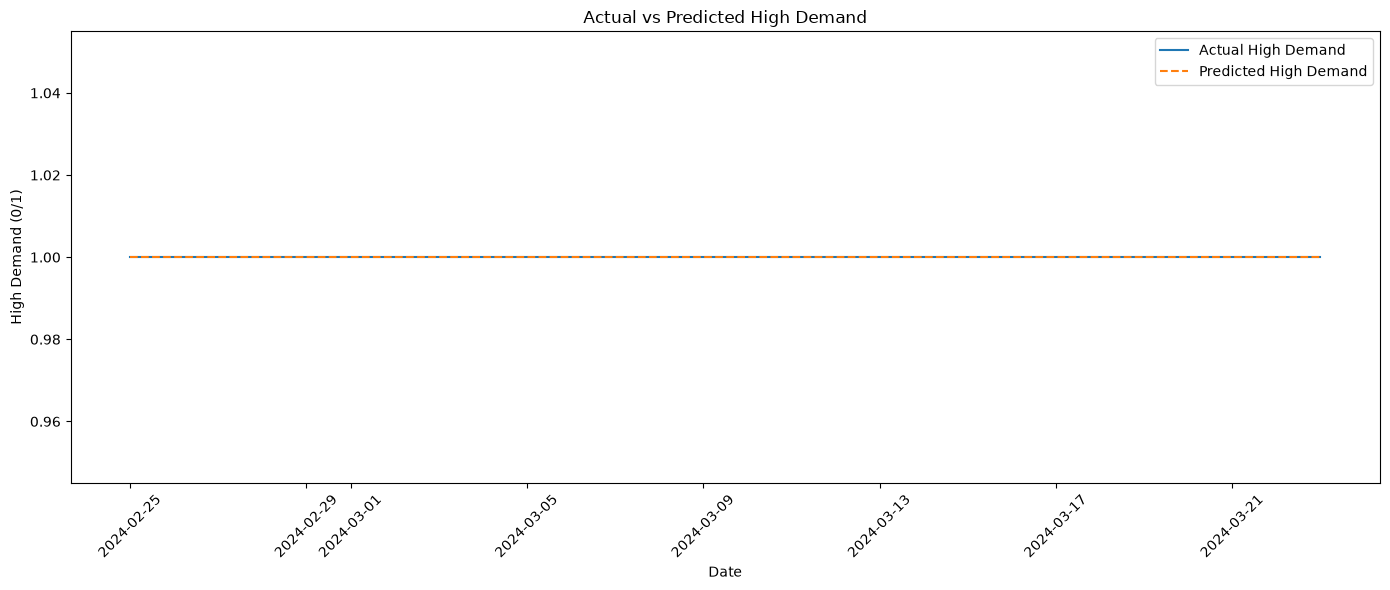

In [170]:
plt.figure(figsize=(14, 6))

plt.plot(
    results["date"],
    results["high_demand"],
    label="Actual High Demand"
)

plt.plot(
    results["date"],
    results["predicted_high_demand"],
    linestyle="--",
    label="Predicted High Demand"
)

plt.title("Actual vs Predicted High Demand")
plt.xlabel("Date")
plt.ylabel("High Demand (0/1)")
plt.xticks(rotation=45)
plt.legend()

plt.tight_layout()
plt.show()

In [171]:
high_demand_summary = (
    results[
        results["predicted_high_demand"] == 1
    ]
    .groupby("job_category")
    .size()
    .reset_index(name="Predicted_High_Demand_Days")
    .sort_values(
        "Predicted_High_Demand_Days",
        ascending=False
    )
)

high_demand_summary

,job_category,Predicted_High_Demand_Days
2,Data & Analytics,28
6,Marketing,28
10,Web Development,28
0,AI & Machine Learning,27
3,Design,27
1,Customer Support & Admin,27
5,Finance & Accounting,27
4,Engineering,27
7,Other,27
8,Sales & Business Development,27


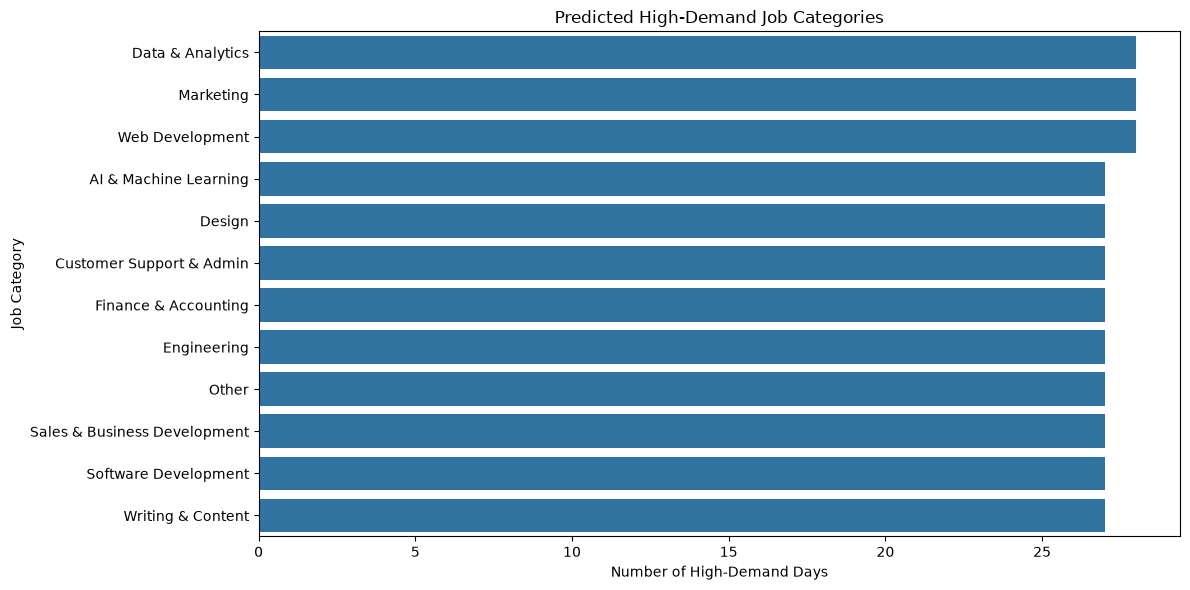

In [172]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=high_demand_summary,
    x="Predicted_High_Demand_Days",
    y="job_category"
)

plt.title("Predicted High-Demand Job Categories")
plt.xlabel("Number of High-Demand Days")
plt.ylabel("Job Category")

plt.tight_layout()
plt.show()

In [173]:
os.makedirs("../reports", exist_ok=True)

results.to_csv(
    "../reports/task3_high_demand_predictions.csv",
    index=False
)

high_demand_summary.to_csv(
    "../reports/task3_high_demand_categories.csv",
    index=False
)

feature_importance.to_csv(
    "../reports/task3_feature_importance.csv",
    index=False
)

print("Task 3 reports saved successfully!")

Task 3 reports saved successfully!


In [174]:
os.makedirs("../models", exist_ok=True)

In [175]:
MODEL_PATH = "../models/high_demand_job_model.pkl"

joblib.dump(
    rf_model,
    MODEL_PATH
)

print("Model saved successfully!")
print(MODEL_PATH)

Model saved successfully!
../models/high_demand_job_model.pkl


In [176]:
metrics = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score"
    ],
    "Score": [
        accuracy,
        precision,
        recall,
        f1
    ]
})

metrics

,Metric,Score
0,Accuracy,1.0
1,Precision,1.0
2,Recall,1.0
3,F1 Score,1.0


In [177]:
metrics.to_csv(
    "../reports/task3_model_metrics.csv",
    index=False
)

print("Model metrics saved successfully!")

Model metrics saved successfully!


In [178]:
metrics.to_csv(
    "../reports/task3_model_metrics.csv",
    index=False
)

print("Model metrics saved successfully!")

Model metrics saved successfully!


In [179]:
print(df.columns.tolist())

['title', 'link', 'published_date', 'is_hourly', 'hourly_low', 'hourly_high', 'budget', 'country', 'clean_job_title', 'job_category']


In [180]:
possible_country_columns = [
    col for col in df.columns
    if any(keyword in col.lower()
           for keyword in [
               "country",
               "location",
               "client_country",
               "client_location"
           ])
]

print("Possible country columns:")
print(possible_country_columns)

Possible country columns:
['country']


In [181]:
COUNTRY_COLUMN = "country"

In [182]:
COUNTRY_COLUMN = "client_country"

In [183]:
possible_rate_columns = [
    col for col in df.columns
    if any(keyword in col.lower()
           for keyword in [
               "hourly",
               "rate",
               "salary",
               "budget",
               "amount",
               "price"
           ])
]

print("Possible rate columns:")
print(possible_rate_columns)

Possible rate columns:
['is_hourly', 'hourly_low', 'hourly_high', 'budget']


In [184]:
RATE_COLUMN = "hourly_rate"

In [185]:
# Resolve column names safely
COUNTRY_COLUMN = (
    "country"
    if "country" in df.columns
    else "client_country" if "client_country" in df.columns
    else None
)

RATE_COLUMN = next(
    (col for col in ["hourly_low", "hourly_high", "budget", "hourly_rate"]
     if col in df.columns),
    None
)

if COUNTRY_COLUMN is not None and RATE_COLUMN is not None:
    print(df[[COUNTRY_COLUMN, RATE_COLUMN]].head(20))
else:
    print("No valid country/rate columns found.")
    print("Available columns:", df.columns.tolist())

           country  hourly_low
0              NaN         NaN
1    United States         NaN
2    United States        10.0
3    United States         NaN
4            India         NaN
5         Portugal         NaN
6            India         NaN
7            India         7.0
8          Germany         NaN
9           Canada         NaN
10         Germany         NaN
11   United States         NaN
12       Singapore         NaN
13  United Kingdom        40.0
14         Denmark         NaN
15        Malaysia        30.0
16   United States         NaN
17      Bangladesh         NaN
18           India        12.0
19          Canada         4.0


In [186]:
print("Number of unique countries:",
      df[COUNTRY_COLUMN].nunique())

Number of unique countries: 212


In [187]:
print(
    df[COUNTRY_COLUMN]
    .value_counts()
    .head(20)
)

country
United States           99834
United Kingdom          19149
India                   15835
Australia               12618
Canada                  11658
Pakistan                 5291
Germany                  4844
Netherlands              4435
United Arab Emirates     4039
France                   3163
Spain                    2519
Singapore                2501
Philippines              2426
China                    2157
Israel                   2082
Ukraine                  2062
Italy                    1791
Bangladesh               1767
Switzerland              1767
Saudi Arabia             1706
Name: count, dtype: int64


In [188]:
df[COUNTRY_COLUMN] = (
    df[COUNTRY_COLUMN]
    .astype(str)
    .str.strip()
)

In [189]:
df[COUNTRY_COLUMN].value_counts().head(20)

country
United States           99834
United Kingdom          19149
India                   15835
Australia               12618
Canada                  11658
Pakistan                 5291
Germany                  4844
Netherlands              4435
United Arab Emirates     4039
France                   3163
Spain                    2519
Singapore                2501
Philippines              2426
China                    2157
Israel                   2082
Ukraine                  2062
Italy                    1791
Bangladesh               1767
Switzerland              1767
Saudi Arabia             1706
Name: count, dtype: int64

In [190]:
def extract_numeric_rate(value):

    if pd.isna(value):
        return np.nan

    value = str(value)

    value = value.replace(",", "")

    numbers = re.findall(
        r"\d+(?:\.\d+)?",
        value
    )

    if not numbers:
        return np.nan

    numbers = [float(x) for x in numbers]

    # If range is provided, use average
    if len(numbers) >= 2:
        return np.mean(numbers[:2])

    return numbers[0]

In [191]:
def extract_numeric_rate(value):

    if pd.isna(value):
        return np.nan

    value = str(value)

    value = value.replace(",", "")

    numbers = re.findall(
        r"\d+(?:\.\d+)?",
        value
    )

    if not numbers:
        return np.nan

    numbers = [float(x) for x in numbers]

    # If range is provided, use average
    if len(numbers) >= 2:
        return np.mean(numbers[:2])

    return numbers[0]

In [192]:
df["hourly_rate_numeric"] = (
    df[RATE_COLUMN]
    .apply(extract_numeric_rate)
)

In [193]:
print(
    df[
        [RATE_COLUMN, "hourly_rate_numeric"]
    ].head(20)
)

    hourly_low  hourly_rate_numeric
0          NaN                  NaN
1          NaN                  NaN
2         10.0                 10.0
3          NaN                  NaN
4          NaN                  NaN
5          NaN                  NaN
6          NaN                  NaN
7          7.0                  7.0
8          NaN                  NaN
9          NaN                  NaN
10         NaN                  NaN
11         NaN                  NaN
12         NaN                  NaN
13        40.0                 40.0
14         NaN                  NaN
15        30.0                 30.0
16         NaN                  NaN
17         NaN                  NaN
18        12.0                 12.0
19         4.0                  4.0


In [194]:
print(
    "Missing hourly rates:",
    df["hourly_rate_numeric"].isna().sum()
)

Missing hourly rates: 142406


In [195]:
missing_rate_percentage = (
    df["hourly_rate_numeric"].isna().mean() * 100
)

print(
    "Missing Rate Percentage:",
    round(missing_rate_percentage, 2),
    "%"
)

Missing Rate Percentage: 58.17 %


In [196]:
rate_df = df[
    [
        COUNTRY_COLUMN,
        "hourly_rate_numeric"
    ]
].dropna()

rate_df = rate_df[
    rate_df[COUNTRY_COLUMN].str.lower()
    != "nan"
]

print("Rows available for rate analysis:",
      len(rate_df))

Rows available for rate analysis: 100408


In [197]:
country_rate_summary = (
    rate_df
    .groupby(COUNTRY_COLUMN)
    .agg(
        Job_Postings=(
            "hourly_rate_numeric",
            "count"
        ),
        Average_Hourly_Rate=(
            "hourly_rate_numeric",
            "mean"
        ),
        Median_Hourly_Rate=(
            "hourly_rate_numeric",
            "median"
        ),
        Minimum_Hourly_Rate=(
            "hourly_rate_numeric",
            "min"
        ),
        Maximum_Hourly_Rate=(
            "hourly_rate_numeric",
            "max"
        )
    )
    .reset_index()
)

In [198]:
country_rate_summary = (
    country_rate_summary
    .sort_values(
        "Average_Hourly_Rate",
        ascending=False
    )
)

country_rate_summary.head(20)

,country,Job_Postings,Average_Hourly_Rate,Median_Hourly_Rate,Minimum_Hourly_Rate,Maximum_Hourly_Rate
104,Malawi,3,59.333333,22.0,6.0,150.0
53,Eritrea,1,50.000000,50.0,50.0,50.0
175,Turks and Caicos Islands,4,31.000000,27.5,19.0,50.0
59,French Guiana,1,28.000000,28.0,28.0,28.0
95,Laos,4,26.500000,26.5,3.0,50.0
112,"Micronesia, Federated States of",1,25.000000,25.0,25.0,25.0
123,Netherlands Antilles,2,22.500000,22.5,15.0,30.0
25,British Virgin Islands,9,22.222222,20.0,5.0,40.0
91,Kenya,369,22.075881,20.0,3.0,150.0
151,Senegal,9,21.111111,15.0,10.0,55.0


In [199]:
country_rate_filtered = country_rate_summary[
    country_rate_summary["Job_Postings"] >= 5
].copy()

print(
    "Countries after minimum posting filter:",
    len(country_rate_filtered)
)

Countries after minimum posting filter: 143


In [200]:
country_rate_filtered.head(20)

,country,Job_Postings,Average_Hourly_Rate,Median_Hourly_Rate,Minimum_Hourly_Rate,Maximum_Hourly_Rate
25,British Virgin Islands,9,22.222222,20.0,5.0,40.0
91,Kenya,369,22.075881,20.0,3.0,150.0
151,Senegal,9,21.111111,15.0,10.0,55.0
189,Zambia,22,20.272727,15.0,3.0,50.0
32,Cayman Islands,16,19.937500,17.5,3.0,50.0
180,United States,48195,19.778857,15.0,3.0,998.0
65,Gibraltar,9,19.777778,15.0,4.0,50.0
81,Indonesia,234,19.388889,12.0,3.0,900.0
34,Chile,48,19.208333,15.0,3.0,150.0
44,Cyprus,167,18.820359,15.0,3.0,400.0


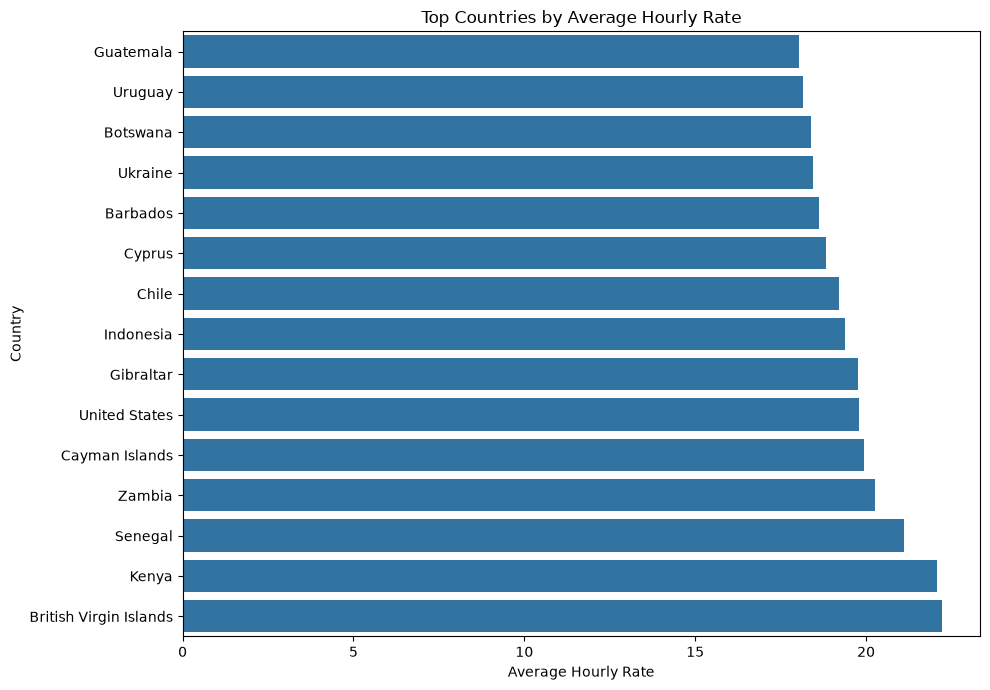

In [201]:
top_countries = (
    country_rate_filtered
    .head(15)
    .sort_values(
        "Average_Hourly_Rate"
    )
)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_countries,
    x="Average_Hourly_Rate",
    y=COUNTRY_COLUMN
)

plt.title(
    "Top Countries by Average Hourly Rate"
)

plt.xlabel("Average Hourly Rate")
plt.ylabel("Country")

plt.tight_layout()
plt.show()

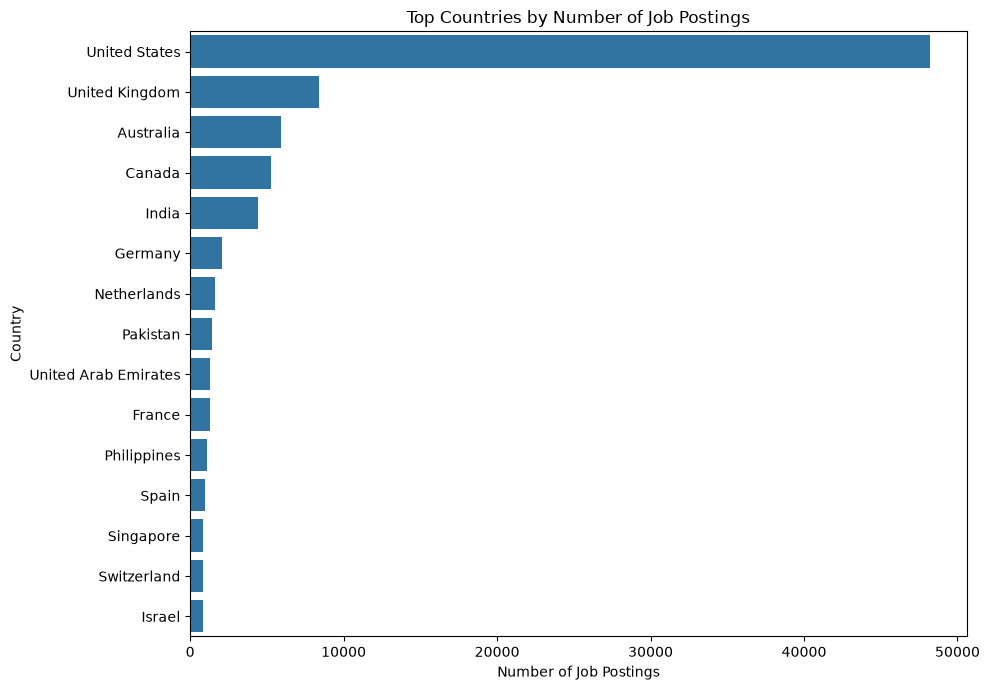

In [202]:
top_posting_countries = (
    country_rate_summary
    .sort_values(
        "Job_Postings",
        ascending=False
    )
    .head(15)
)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_posting_countries,
    x="Job_Postings",
    y=COUNTRY_COLUMN
)

plt.title(
    "Top Countries by Number of Job Postings"
)

plt.xlabel("Number of Job Postings")
plt.ylabel("Country")

plt.tight_layout()
plt.show()

In [203]:
fig = px.bar(
    country_rate_filtered.head(20),
    x="Average_Hourly_Rate",
    y=COUNTRY_COLUMN,
    orientation="h",
    title="Average Hourly Rate by Country",
    hover_data=[
        "Job_Postings",
        "Median_Hourly_Rate",
        "Minimum_Hourly_Rate",
        "Maximum_Hourly_Rate"
    ]
)

fig.update_layout(
    height=700,
    xaxis_title="Average Hourly Rate",
    yaxis_title="Country"
)

fig.show()

In [204]:
fig = px.choropleth(
    country_rate_filtered,
    locations=COUNTRY_COLUMN,
    locationmode="country names",
    color="Average_Hourly_Rate",
    hover_name=COUNTRY_COLUMN,
    hover_data={
        "Job_Postings": True,
        "Average_Hourly_Rate": ":.2f",
        "Median_Hourly_Rate": ":.2f",
        "Minimum_Hourly_Rate": ":.2f",
        "Maximum_Hourly_Rate": ":.2f"
    },
    title="Average Hourly Rate by Country"
)

fig.update_layout(
    height=700
)

fig.show()

In [205]:
country_mapping = {
    "USA": "United States",
    "US": "United States",
    "UK": "United Kingdom",
    "UAE": "United Arab Emirates",
    "IN": "India"
}

df[COUNTRY_COLUMN] = (
    df[COUNTRY_COLUMN]
    .replace(country_mapping)
)

In [206]:
fig = px.scatter(
    country_rate_filtered,
    x="Job_Postings",
    y="Average_Hourly_Rate",
    size="Job_Postings",
    hover_name=COUNTRY_COLUMN,
    title="Job Posting Volume vs Average Hourly Rate",
    labels={
        "Job_Postings": "Number of Job Postings",
        "Average_Hourly_Rate":
            "Average Hourly Rate"
    }
)

fig.show()

In [207]:
import os

os.makedirs("../reports", exist_ok=True)

In [208]:
country_rate_summary.to_csv(
    "../reports/task4_country_hourly_rate_analysis.csv",
    index=False
)

country_rate_filtered.to_csv(
    "../reports/task4_country_hourly_rate_filtered.csv",
    index=False
)

print("Task 4 reports saved successfully!")

Task 4 reports saved successfully!


In [209]:
fig = px.choropleth(
    country_rate_filtered,
    locations=COUNTRY_COLUMN,
    locationmode="country names",
    color="Average_Hourly_Rate",
    hover_name=COUNTRY_COLUMN,
    hover_data=[
        "Job_Postings",
        "Median_Hourly_Rate",
        "Minimum_Hourly_Rate",
        "Maximum_Hourly_Rate"
    ],
    title="Average Hourly Rate by Country"
)

fig.write_html(
    "../reports/task4_country_hourly_rate_map.html"
)

print("Interactive map saved successfully!")

Interactive map saved successfully!


In [210]:
DATA_PATH = "../data/cleaned_job_market_data_v2.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

df.head()

Dataset loaded successfully!
Rows: 244828
Columns: 10


,title,link,published_date,is_hourly,hourly_low,hourly_high,budget,country,clean_job_title,job_category
0,Experienced Media Buyer For Solar Pannel and R...,https://www.upwork.com/jobs/Experienced-Media-...,2024-02-17 09:09:54+00:00,False,NaN,NaN,500.0,NaN,experienced media buyer for solar pannel and r...,Other
1,Full Stack Developer,https://www.upwork.com/jobs/Full-Stack-Develop...,2024-02-17 09:09:17+00:00,False,NaN,NaN,1100.0,United States,full stack developer,Software Development
2,SMMA Bubble App,https://www.upwork.com/jobs/SMMA-Bubble-App_%7...,2024-02-17 09:08:46+00:00,True,10.0,30.0,NaN,United States,smma bubble app,Other
3,Talent Hunter Specialized in Marketing,https://www.upwork.com/jobs/Talent-Hunter-Spec...,2024-02-17 09:08:08+00:00,True,NaN,NaN,NaN,United States,talent hunter specialized in marketing,Marketing
4,Data Engineer,https://www.upwork.com/jobs/Data-Engineer_%7E0...,2024-02-17 09:07:42+00:00,False,NaN,NaN,650.0,India,data engineer,Data & Analytics


In [211]:
print(df.columns.tolist())

['title', 'link', 'published_date', 'is_hourly', 'hourly_low', 'hourly_high', 'budget', 'country', 'clean_job_title', 'job_category']


In [212]:
possible_title_columns = [
    col for col in df.columns
    if any(keyword in col.lower()
           for keyword in [
               "title",
               "job_title",
               "jobtitle"
           ])
]

print("Possible Job Title columns:")
print(possible_title_columns)

Possible Job Title columns:
['title', 'clean_job_title']


In [213]:
possible_description_columns = [
    col for col in df.columns
    if any(keyword in col.lower()
           for keyword in [
               "description",
               "details",
               "summary",
               "overview"
           ])
]

print("Possible Description columns:")
print(possible_description_columns)

Possible Description columns:
[]


In [214]:
JOB_TITLE_COLUMN = "title"
DESCRIPTION_COLUMN = "description"

In [215]:
# Resolve available title/description columns safely
JOB_TITLE_COLUMN = (
    "title"
    if "title" in df.columns
    else "clean_job_title" if "clean_job_title" in df.columns
    else None
)

description_candidates = [
    col for col in df.columns
    if any(keyword in col.lower()
           for keyword in ["description", "details", "summary", "overview"])
]

DESCRIPTION_COLUMN = description_candidates[0] if description_candidates else None

if JOB_TITLE_COLUMN is None:
    raise KeyError("No title-like column found in dataframe.")

if DESCRIPTION_COLUMN is not None:
    print(
        df[[JOB_TITLE_COLUMN, DESCRIPTION_COLUMN]]
        .head(10)
    )
else:
    print(
        df[[JOB_TITLE_COLUMN]]
        .head(10)
    )
    print("No description-like column found in the dataset; title column shown instead.")

                                               title
0  Experienced Media Buyer For Solar Pannel and R...
1                               Full Stack Developer
2                                    SMMA Bubble App
3             Talent Hunter Specialized in Marketing
4                                      Data Engineer
5               SEO for Portuguese Psychologist site
6                   Want to fix the WordPress Plugin
7  need Portuguese writers who can understand and...
8  Looker Studio Dashboard for Leadgen and E-Comm...
9  PHP/HTML/CSS WordPress Developer Needed for We...
No description-like column found in the dataset; title column shown instead.


In [216]:
df[JOB_TITLE_COLUMN] = (
    df[JOB_TITLE_COLUMN]
    .fillna("")
    .astype(str)
)

if DESCRIPTION_COLUMN is not None:
    df[DESCRIPTION_COLUMN] = (
        df[DESCRIPTION_COLUMN]
        .fillna("")
        .astype(str)
    )
else:
    print("No description-like column found; skipping description cleaning.")

No description-like column found; skipping description cleaning.


In [217]:
import pandas as pd

# Ensure df exists in the notebook state
if "df" not in globals():
    DATA_PATH = "../data/cleaned_job_market_data_v2.csv"
    df = pd.read_csv(DATA_PATH)

# Resolve title and description columns safely
if "JOB_TITLE_COLUMN" not in globals() or JOB_TITLE_COLUMN not in df.columns:
    JOB_TITLE_COLUMN = (
        "title"
        if "title" in df.columns
        else "clean_job_title"
        if "clean_job_title" in df.columns
        else None
    )

if "DESCRIPTION_COLUMN" not in globals() or DESCRIPTION_COLUMN not in df.columns:
    description_candidates = [
        col for col in df.columns
        if any(keyword in col.lower()
               for keyword in ["description", "details", "summary", "overview"])
    ]
    DESCRIPTION_COLUMN = description_candidates[0] if description_candidates else None

if JOB_TITLE_COLUMN is None:
    raise KeyError("No title-like column found in the dataframe.")

# Clean text columns
df[JOB_TITLE_COLUMN] = df[JOB_TITLE_COLUMN].fillna("").astype(str)

if DESCRIPTION_COLUMN is not None:
    df[DESCRIPTION_COLUMN] = df[DESCRIPTION_COLUMN].fillna("").astype(str)
    df["job_text"] = (
        df[JOB_TITLE_COLUMN].fillna("")
        + " "
        + df[DESCRIPTION_COLUMN].fillna("")
    )
else:
    df["job_text"] = df[JOB_TITLE_COLUMN].fillna("")

df[["job_text"]].head()

,job_text
0,Experienced Media Buyer For Solar Pannel and R...
1,Full Stack Developer
2,SMMA Bubble App
3,Talent Hunter Specialized in Marketing
4,Data Engineer


In [218]:
print(df["job_text"].head())

0    Experienced Media Buyer For Solar Pannel and R...
1                                 Full Stack Developer
2                                      SMMA Bubble App
3               Talent Hunter Specialized in Marketing
4                                        Data Engineer
Name: job_text, dtype: str


In [219]:
def clean_text(text):

    text = str(text).lower()

    # Remove URLs
    text = re.sub(
        r"http\S+|www\S+|https\S+",
        " ",
        text
    )

    # Remove special characters
    text = re.sub(
        r"[^a-zA-Z0-9\s]",
        " ",
        text
    )

    # Remove extra spaces
    text = re.sub(
        r"\s+",
        " ",
        text
    ).strip()

    return text

In [220]:
import re

df["clean_job_text"] = (
    df["job_text"]
    .apply(clean_text)
)

In [221]:
df[
    [
        JOB_TITLE_COLUMN,
        "clean_job_text"
    ]
].head()

,title,clean_job_text
0,Experienced Media Buyer For Solar Pannel and R...,experienced media buyer for solar pannel and r...
1,Full Stack Developer,full stack developer
2,SMMA Bubble App,smma bubble app
3,Talent Hunter Specialized in Marketing,talent hunter specialized in marketing
4,Data Engineer,data engineer


In [222]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    stop_words="english",
    max_features=10000,
    ngram_range=(1, 2)
)

job_vectors = tfidf.fit_transform(
    df["clean_job_text"]
)

print(
    "TF-IDF Matrix Shape:",
    job_vectors.shape
)

job_vectors = tfidf.fit_transform(
    df["clean_job_text"]
)

print(
    "TF-IDF Matrix Shape:",
    job_vectors.shape
)

TF-IDF Matrix Shape: (244828, 10000)
TF-IDF Matrix Shape: (244828, 10000)


In [223]:
def recommend_jobs(
    user_profile,
    top_n=10
):

    user_profile_clean = clean_text(
        user_profile
    )

    user_vector = tfidf.transform(
        [user_profile_clean]
    )

    similarity_scores = cosine_similarity(
        user_vector,
        job_vectors
    ).flatten()

    top_indices = (
        similarity_scores
        .argsort()[-top_n:][::-1]
    )

    recommendations = df.iloc[
        top_indices
    ].copy()

    recommendations[
        "similarity_score"
    ] = similarity_scores[top_indices]

    return recommendations

In [224]:
from sklearn.metrics.pairwise import cosine_similarity

user_profile = """
Data Scientist
Python SQL Machine Learning
Pandas NumPy Scikit-learn
Data Analysis
Data Visualization
Power BI
Statistics
"""

recommendations = recommend_jobs(
    user_profile,
    top_n=10
)

recommendations[
    [
        JOB_TITLE_COLUMN,
        "similarity_score"
    ]
]

,title,similarity_score
214395,Machine Learning - Data Scientist,0.594209
201443,"Data Scientist for Data Cleaning, Data Analysi...",0.586962
150250,Data visualization update in Power BI,0.565486
41316,Power BI Dashboards for data visualization,0.534728
178773,Data Visualization and Power BI/Tableau Expert,0.529407
117431,Teaching Data Scientist &amp; Machine Learning,0.518522
11580,Power BI - Data Visualization,0.516494
166276,Power BI - Data Visualization,0.516494
77445,Data Scientist Needed for Python Analysis,0.515237
17034,Data Scientist for Client POS Data Analysis,0.509034


In [225]:
display_columns = [
    JOB_TITLE_COLUMN
]

if "job_category" in recommendations.columns:
    display_columns.append(
        "job_category"
    )

if "country" in recommendations.columns:
    display_columns.append(
        "country"
    )

display_columns.append(
    "similarity_score"
)

recommendations[
    display_columns
]

,title,job_category,country,similarity_score
214395,Machine Learning - Data Scientist,Data & Analytics,United States,0.594209
201443,"Data Scientist for Data Cleaning, Data Analysi...",Data & Analytics,Canada,0.586962
150250,Data visualization update in Power BI,Other,Latvia,0.565486
41316,Power BI Dashboards for data visualization,Other,Pakistan,0.534728
178773,Data Visualization and Power BI/Tableau Expert,Other,United States,0.529407
117431,Teaching Data Scientist &amp; Machine Learning,Data & Analytics,United States,0.518522
11580,Power BI - Data Visualization,Other,United States,0.516494
166276,Power BI - Data Visualization,Other,United States,0.516494
77445,Data Scientist Needed for Python Analysis,Data & Analytics,Nigeria,0.515237
17034,Data Scientist for Client POS Data Analysis,Data & Analytics,Canada,0.509034


In [226]:
recommendations[
    "match_percentage"
] = (
    recommendations[
        "similarity_score"
    ] * 100
).round(2)

In [227]:
recommendations[
    [
        JOB_TITLE_COLUMN,
        "match_percentage"
    ]
]

,title,match_percentage
214395,Machine Learning - Data Scientist,59.42
201443,"Data Scientist for Data Cleaning, Data Analysi...",58.70
150250,Data visualization update in Power BI,56.55
41316,Power BI Dashboards for data visualization,53.47
178773,Data Visualization and Power BI/Tableau Expert,52.94
117431,Teaching Data Scientist &amp; Machine Learning,51.85
11580,Power BI - Data Visualization,51.65
166276,Power BI - Data Visualization,51.65
77445,Data Scientist Needed for Python Analysis,51.52
17034,Data Scientist for Client POS Data Analysis,50.90


In [228]:
possible_url_columns = [
    col for col in df.columns
    if any(keyword in col.lower()
           for keyword in [
               "url",
               "link",
               "href"
           ])
]

print("Possible URL columns:")
print(possible_url_columns)

Possible URL columns:
['link', 'is_hourly', 'hourly_low', 'hourly_high']


In [229]:
JOB_URL_COLUMN = "job_url"

In [230]:
if possible_url_columns:

    JOB_URL_COLUMN = possible_url_columns[0]

    display_columns = [
        JOB_TITLE_COLUMN,
        JOB_URL_COLUMN,
        "match_percentage"
    ]

    recommendations[
        display_columns
    ]

In [231]:
recommendation_output = recommendations.copy()

recommendation_output[
    "match_percentage"
] = (
    recommendation_output[
        "similarity_score"
    ] * 100
).round(2)

recommendation_output = (
    recommendation_output
    .sort_values(
        "match_percentage",
        ascending=False
    )
)

In [232]:
import os

os.makedirs("../reports", exist_ok=True)


In [233]:
recommendation_output.to_csv(
    "../reports/job_recommendations.csv",
    index=False
)

print(
    "Recommendations saved successfully!"
)

Recommendations saved successfully!


In [234]:
os.makedirs(
    "../models",
    exist_ok=True
)

In [235]:
import os
import joblib

os.makedirs("../models", exist_ok=True)

joblib.dump(
    tfidf,
    "../models/job_tfidf_vectorizer.pkl"
)

print("TF-IDF vectorizer saved successfully!")

TF-IDF vectorizer saved successfully!


In [236]:
joblib.dump(
    job_vectors,
    "../models/job_vectors.pkl"
)

['../models/job_vectors.pkl']

In [237]:
df.to_pickle(
    "../models/recommendation_jobs.pkl"
)

In [238]:
import pandas as pd
import numpy as np
import re
import joblib

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity


def clean_text(text):

    text = str(text).lower()

    text = re.sub(
        r"http\S+|www\S+|https\S+",
        " ",
        text
    )

    text = re.sub(
        r"[^a-zA-Z0-9\s]",
        " ",
        text
    )

    text = re.sub(
        r"\s+",
        " ",
        text
    ).strip()

    return text


def recommend_jobs(
    user_profile,
    df,
    tfidf,
    job_vectors,
    top_n=10
):

    user_profile = clean_text(
        user_profile
    )

    user_vector = tfidf.transform(
        [user_profile]
    )

    similarity_scores = cosine_similarity(
        user_vector,
        job_vectors
    ).flatten()

    top_indices = (
        similarity_scores
        .argsort()[-top_n:][::-1]
    )

    recommendations = df.iloc[
        top_indices
    ].copy()

    recommendations[
        "similarity_score"
    ] = similarity_scores[top_indices]

    recommendations[
        "match_percentage"
    ] = (
        recommendations[
            "similarity_score"
        ] * 100
    ).round(2)

    return recommendations